In [6]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Основные библиотеки

In [4]:
import torch
import torch.nn as nn

from sklearn.model_selection import KFold
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score


from matplotlib.ticker import AutoMinorLocator, MultipleLocator

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import OrdinalEncoder

from sklearn.utils import check_random_state

import os
import json
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from pathlib import Path

import pandas as pd
import mlflow
from mlflow import MlflowClient
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn.model_selection

from sklearn.model_selection import KFold
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_validate
from sklearn.base import clone

# GridSearch
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV, ParameterSampler
import optuna

from sklearn.preprocessing import StandardScaler  # уточнить
from sklearn.base import BaseEstimator, TransformerMixin

# Metrics
from sklearn.metrics import root_mean_squared_error
from sklearn.utils.validation import check_is_fitted

# Pipeline
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Models
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.neighbors import KNeighborsRegressor

from sklearn.tree import DecisionTreeRegressor, export_graphviz
from sklearn.ensemble import RandomForestRegressor

from catboost import CatBoostRegressor
from catboost import Pool

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

import shap
import graphviz

import joblib

from tqdm.auto import tqdm
from tqdm_joblib import tqdm_joblib

import mlflow
from mlflow import MlflowClient

import time
import subprocess
import tempfile
from pathlib import Path
from IPython.display import display
import json

import sys
import importlib

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.8.0) or chardet (7.4.3)/charset_normalizer (3.4.3) doesn't match a supported version!
  warnings.warn(


In [7]:
import logging

os.environ["MLFLOW_SUPPRESS_PRINTING_URL_TO_STDOUT"] = "true"

import mlflow

logging.getLogger("mlflow").setLevel(logging.ERROR)

## Импорт локальных библиотек

In [95]:
import src.modeling.train as train
import src.utils.drawings as drawer

from config import Config
from src.core_funcs import (
    setup_validation,
    run_experiment,
    run_optuna_experiment,
    run_shap,
    run_feature_selection,
)
from src.feature.features import (
    FeatureTransformer,
    encoder_transformer,
    DNN_encoder,
)
from src.custom_models.myMLP import (
    MyModel,
    Callback,
    EarlyStopping,
    CheckpointManager,
    RMSELoss,
)
from src.feature.feature_selection import count_off_shap
from src.utils.model_saving import ModelSaver
from src.modeling.predict import Predictor
from src.custom_models.meta_model import MyStackingRidge
from src.utils.mymlflow import Mlflow_logger

[autoreload of src.feature.feature_selection failed: Traceback (most recent call last):
  File "C:\Users\user\AppData\Roaming\Python\Python313\site-packages\IPython\extensions\autoreload.py", line 322, in check
    elif self.deduper_reloader.maybe_reload_module(m):
         ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "C:\Users\user\AppData\Roaming\Python\Python313\site-packages\IPython\extensions\deduperreload\deduperreload.py", line 545, in maybe_reload_module
    new_source_code = f.read()
  File "c:\Program Files\Python313\Lib\encodings\cp1251.py", line 23, in decode
    return codecs.charmap_decode(input,self.errors,decoding_table)[0]
           ~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
UnicodeDecodeError: 'charmap' codec can't decode byte 0x98 in position 858: character maps to <undefined>
]
[autoreload of src.modeling.train failed: Traceback (most recent call last):
  File "C:\Users\user\AppData\Roaming\Python\Python313\site-packages\IPython\extensions\autor

## Валидация

In [9]:
X_train, X_holdout, y_train, y_holdout = setup_validation(
    Config.path_train_data, test_size=0.2
)

## Логирование

In [10]:
# cmd - python -m mlflow server --port 5000
logger = Mlflow_logger("House_Prices_Kaggle")
logger.setup_connection()

Start tracking experiments at http://127.0.0.1:5000


## Baseline

### Первый этап, подбор диапазона поиска гиперпараметров вручную

In [18]:
ridge_pipeline = {
    "ridge": {
        "pipeline": Pipeline(
            [
                ("feature_transform", FeatureTransformer()),
                ("encoder", clone(encoder_transformer)),
                ("scaler", StandardScaler()),
                ("model", Ridge()),
            ]
        ),
        "parameters": {
            "model__alpha": [200, 300, 500],  # np.float64(0.11144234247204798)
            "model__solver": ["saga"],
            "model__max_iter": [1000, 1500, 2000],
            "model__random_state": [Config.seed],
        },
        "search_type": "grid",
        "fit_param": {},
        "n_iter": 1,
        "plot_param": "model__alpha",
        "heatmap_params": ("model__alpha", "model__max_iter"),
        "shap_mode": "linear",
        "cv": 5,
        "n_jobs": -1,
    }
}

Начинаем обучение 9 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF 0.1320589155212296, best mean val RMSE 0.12896324250544833, best_val_std 0.02822138982729356
Best searched params
model__alpha          500
model__max_iter      1000
model__random_state    42
model__solver        saga


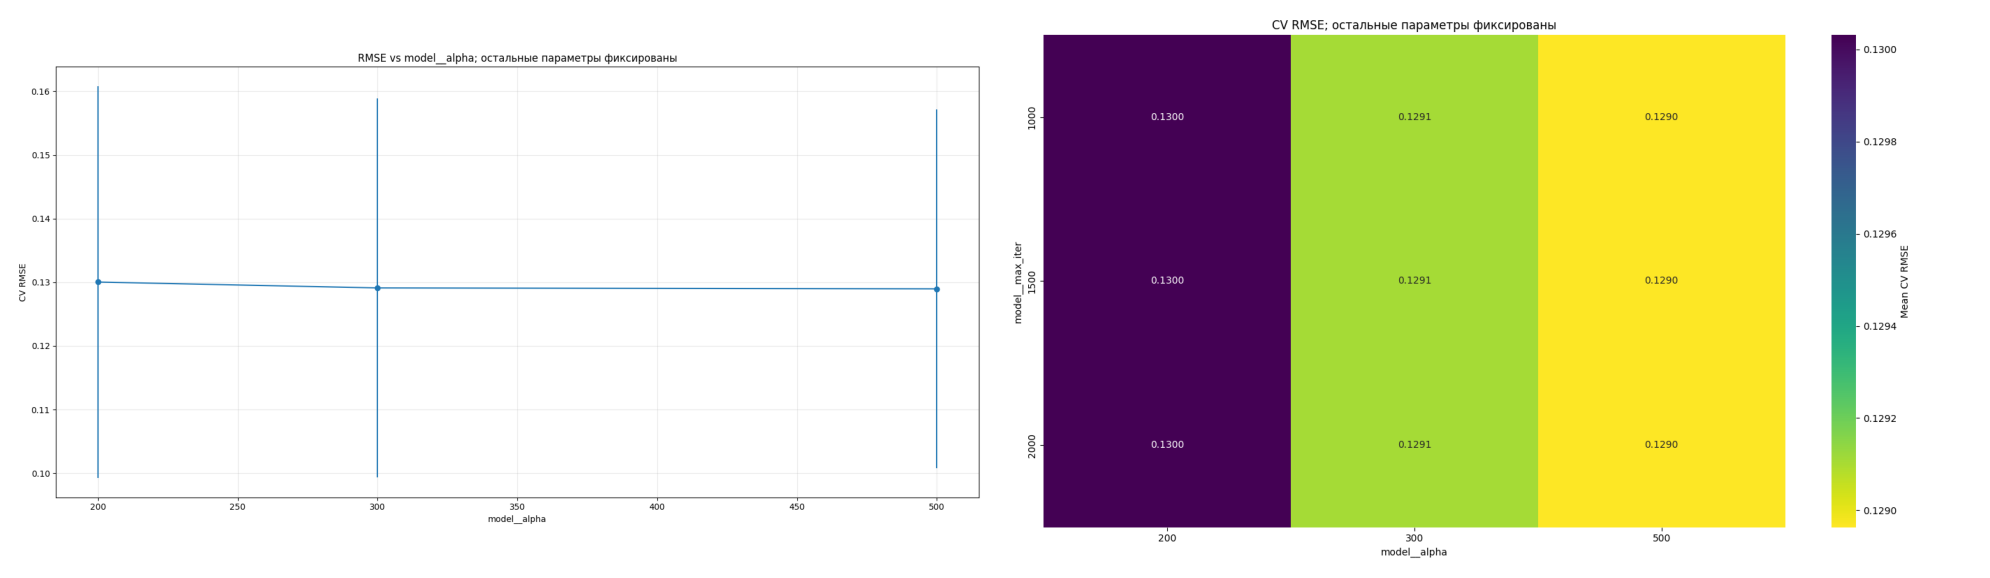

In [19]:
ridge_results = run_experiment(X_train, y_train, "ridge", ridge_pipeline, logger)
ModelSaver.save_ensemble(ridge_results["best_ensemble"], "ridge")

Видно что скор риджа увеличивается с уменьшением параметра регуляризации, но это в целом логично, много параметров могут вносить излишний шум, который линейной модели сложно апроксимировать

### Второй этап, подбор лучших гиперпараметров Optuna

In [150]:
def suggest_ridge_params(trial):
    return {
        "model__alpha": trial.suggest_float(
            "model__alpha",
            20,
            120,
            log=True,
        ),
        "model__max_iter": trial.suggest_int(
            "model__max_iter",
            100,
            1000,
        ),
    }


ridge_optuna_pipeline = {
    "ridge_optuna": {
        "pipeline": Pipeline(
            [
                ("feature_transform", FeatureTransformer()),
                ("encoder", clone(encoder_transformer)),
                ("scaler", StandardScaler()),
                ("model", Ridge()),
            ]
        ),
        "parameters_to_search": suggest_ridge_params,
        "search_type": "grid",
        "fit_param": {"model__solver": "saga", "model__random_state": Config.seed},
        "n_iter": 100,
        "plot_param": "model__alpha",
        "heatmap_params": ("model__alpha", "model__max_iter"),
        "shap_mode": "linear",
        "cv": 5,
        "n_jobs": -1,
    }
}

In [ ]:
# return {
#     "run_id": model_run_id,
#     "results_df": results_df,
#     "best_value": best_value,
#     "best_ensemble": best_ensemble,
#     "best_results": best_results,
#     "best_history": best_history,
#     "figures": double_fig
# }

ridge_optuna_results = run_optuna_experiment(
    X_train, y_train, "ridge_optuna", ridge_optuna_pipeline, logger
)

### Третий этап, подсчет SHAP признаков и отбор признаков

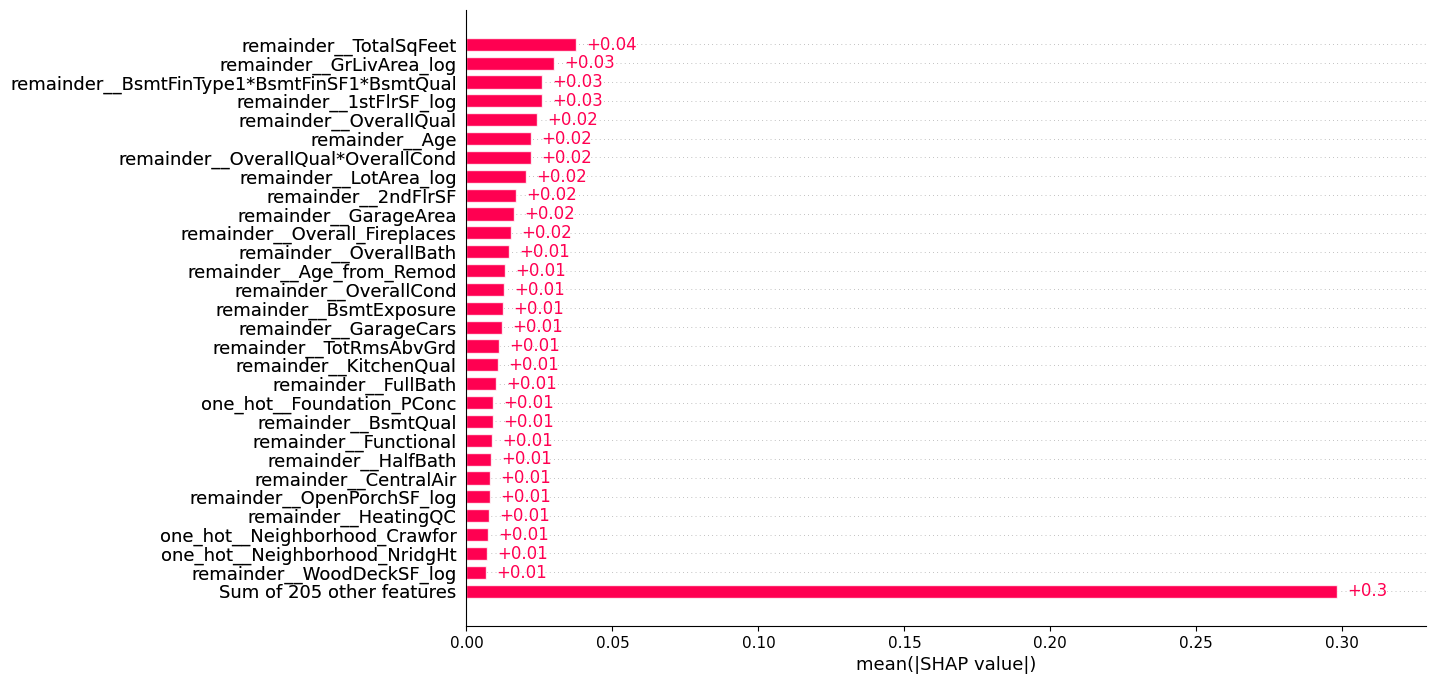

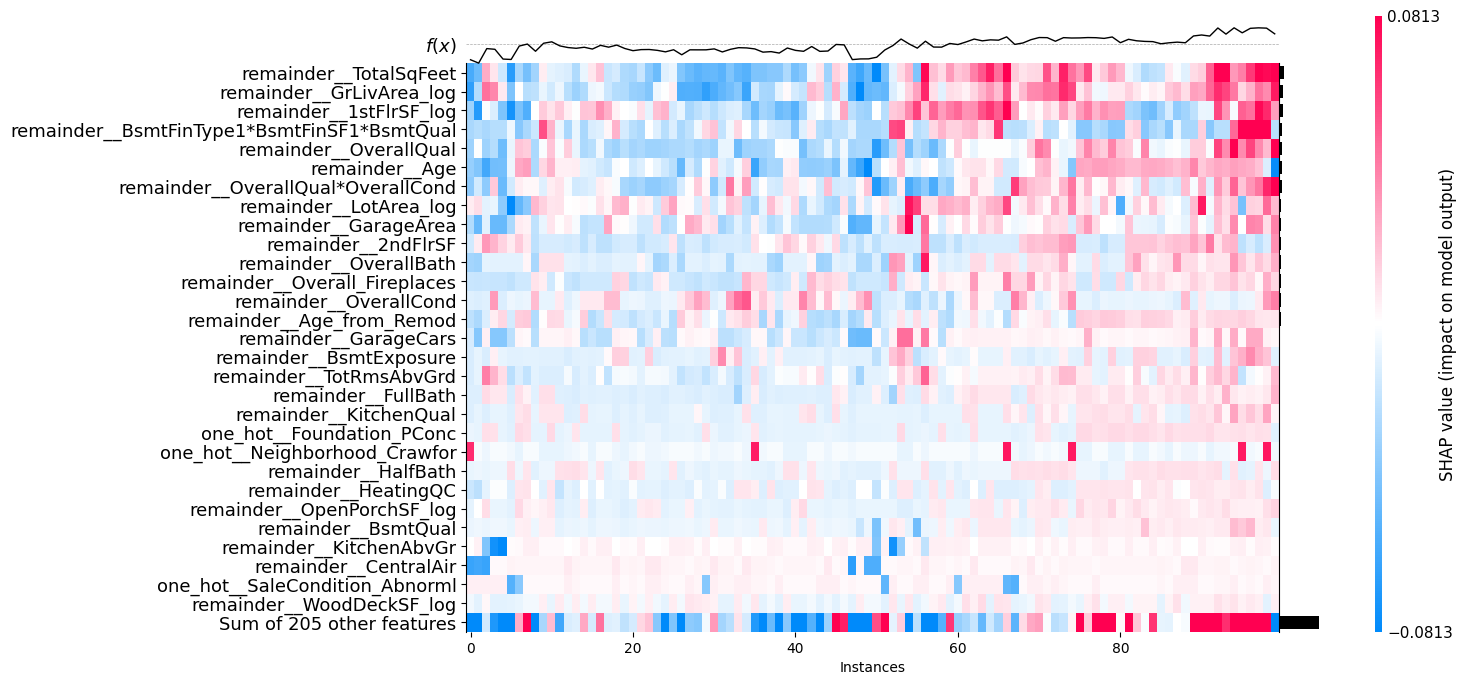

In [13]:
# return {
#     "importance": importance,
#     "oof_explanation": oof_explanation,
#     "figures": figures
# }

ridge_shap = run_shap(X_train, ridge_results, mode="linear", logger=logger)

Из за большой регуляризации модель занизила коэффициенты многих параметров, ключевыми признаками стали общие составные признаки, TotalSqFeet, GrLiveArea_log и составные характеристики подвала. В целом созданные признаки оказились достаточно информативными, что есть хорошо

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF: 0.13526256506550918, best mean val RMSE: 0.13097889033060006, best val std: 0.033565894022737776, best feature amount: 47
-----Best searched params-----
model__alpha          120
model__max_iter      1000
model__random_state    42
model__solver        saga


,params,off_score,mean_val_score,std_val_score,feature_count,split0_val_score,split1_val_score,split2_val_score,split3_val_score,split4_val_score,param_model__alpha,param_model__max_iter,param_model__random_state,param_model__solver,candidate_id
3,"{'model__alpha': 120, 'model__max_iter': 1000,...",0.135263,0.130979,0.033566,174,0.121639,0.140295,0.191082,0.105531,0.096348,120,1000,42,saga,3
4,"{'model__alpha': 120, 'model__max_iter': 1000,...",0.135853,0.131412,0.034243,158,0.122029,0.141980,0.192411,0.102399,0.098240,120,1000,42,saga,4
1,"{'model__alpha': 120, 'model__max_iter': 1000,...",0.136170,0.131913,0.033577,208,0.122707,0.139294,0.192589,0.108999,0.095978,120,1000,42,saga,1
0,"{'model__alpha': 120, 'model__max_iter': 1000,...",0.136270,0.132168,0.032986,223,0.123347,0.136001,0.193062,0.110418,0.098012,120,1000,42,saga,0
2,"{'model__alpha': 120, 'model__max_iter': 1000,...",0.136400,0.132270,0.033104,196,0.123407,0.140405,0.191594,0.109994,0.095951,120,1000,42,saga,2
5,"{'model__alpha': 120, 'model__max_iter': 1000,...",0.137764,0.132982,0.035773,147,0.122490,0.143238,0.197128,0.104634,0.097418,120,1000,42,saga,5
6,"{'model__alpha': 120, 'model__max_iter': 1000,...",0.139379,0.134468,0.036464,115,0.121403,0.145773,0.200110,0.102373,0.102679,120,1000,42,saga,6
7,"{'model__alpha': 120, 'model__max_iter': 1000,...",0.142794,0.137294,0.039044,96,0.123121,0.145116,0.209316,0.107343,0.101574,120,1000,42,saga,7
8,"{'model__alpha': 120, 'model__max_iter': 1000,...",0.151531,0.145607,0.041736,69,0.127697,0.156632,0.222062,0.111787,0.109860,120,1000,42,saga,8


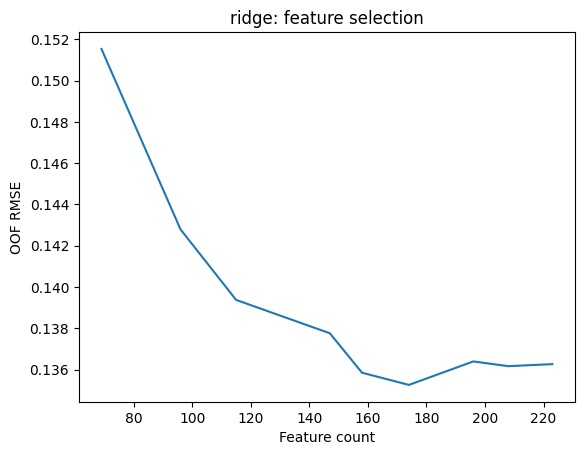

In [14]:
ridge_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=ridge_results["cv_folds"],
    importance=ridge_shap["importance"],
    search_results=ridge_results["best_results"],
    model_name="ridge",
    model_configs=ridge_pipeline,
    model_run_id=ridge_results["run_id"],
    logger=logger,
)

# if ridge_fs_results["best_oof_score"] < ridge_results['best_results']['best_oof_score']:
#     ModelSaver.save_ensemble(ridge_fs_results['best_ensemble'],"ridge", save_fs=ridge_fs_results['best_results']['best_cols'])
# else:
#     ModelSaver.save_ensemble(ridge_results['best_ensemble'],"ridge")

Видим, что отбор признаков чуть учуть улучшил скор, но ридж сам уменьшает потихоньку веса признаков, и часть из них при нашем большом параметре регуляризации уже почти занулились, и поэтому прямой отбор не иммеет тут особо смысла . Учитывая, что мы очень многое делаем на val части CV и отбираем фичи, и подбираем гиперпараметры, в следсвтии чего у нас более оптимистичные показатели CV и есть достаточно приличный шанс на нее оверфитнуться. Для таких вещей нужен nested cv и тогда более объективно отбирать признаки на внутренем валидационом фолде.

## Lasso

In [27]:
lasso_pipeline = {
    "lasso": {
        "pipeline": Pipeline(
            [
                ("feature_transform", FeatureTransformer()),
                ("encoder", clone(encoder_transformer)),
                ("scaler", StandardScaler()),
                ("model", Lasso()),
            ]
        ),
        "parameters": {
            "model__alpha": np.linspace(
                0.001, 0.1, 100
            ),  # np.float64(0.11144234247204798)
            "model__max_iter": [1000],
            "model__random_state": [Config.seed],
        },
        "search_type": "grid",
        "fit_param": {},
        "n_iter": 1,
        "plot_param": "model__alpha",
        "heatmap_params": ("model__alpha", "model__max_iter"),
        "shap_mode": "linear",
        "cv": 5,
        "n_jobs": -1,
    }
}

Начинаем обучение 100 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

... (92 outputs left out)

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF 0.14132422167194805, best mean val RMSE 0.13434912634257426, best_val_std 0.04364354717681818
Best searched params
model__alpha            0.003
model__max_iter      1000.000
model__random_state    42.000


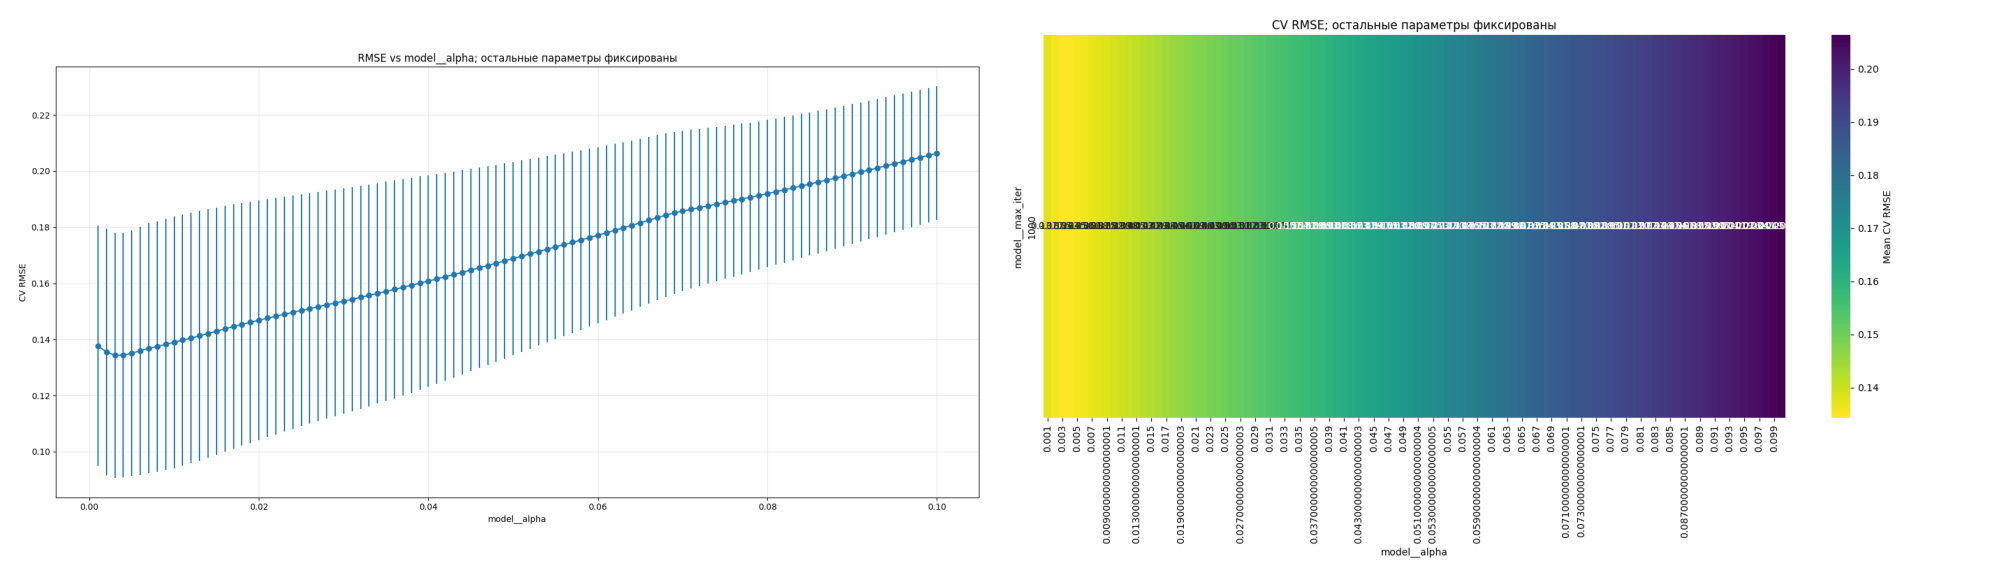

In [28]:
lasso_results = run_experiment(X_train, y_train, "lasso", lasso_pipeline, logger)

ModelSaver.save_ensemble(lasso_results["best_ensemble"], "lasso")

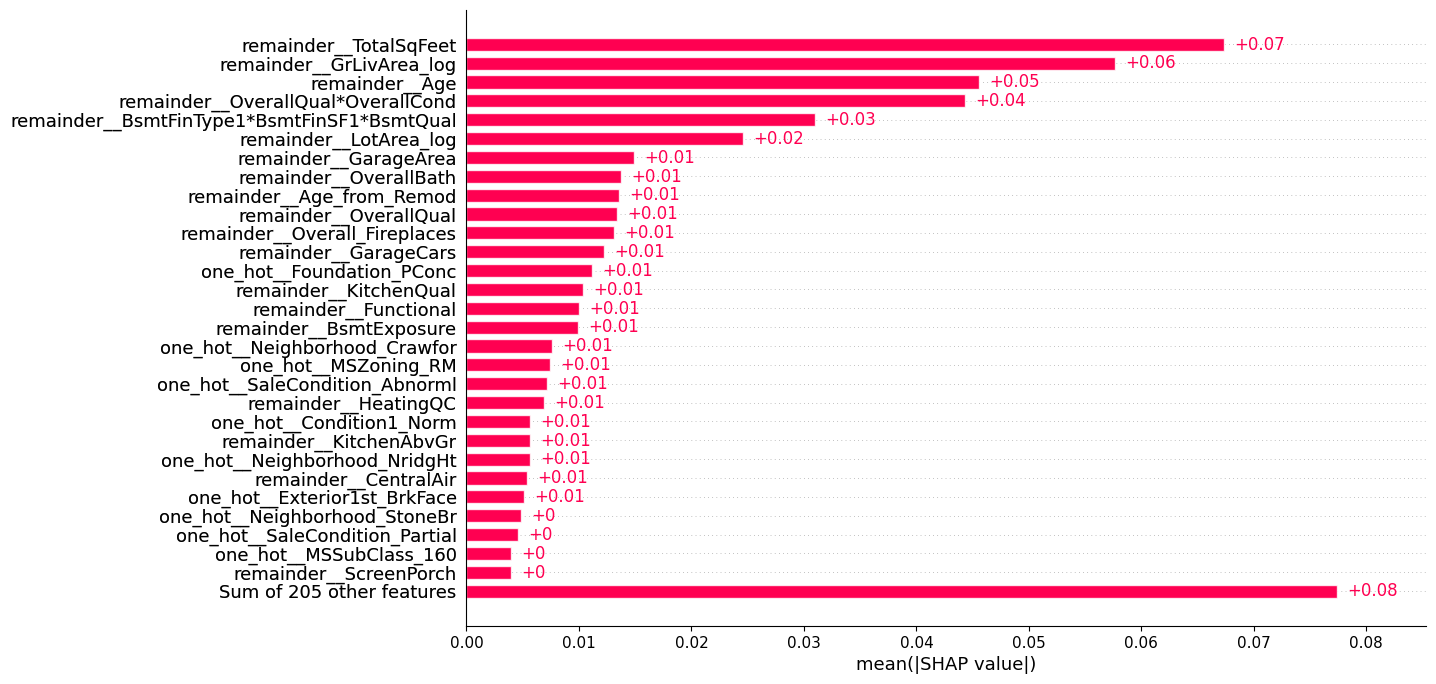

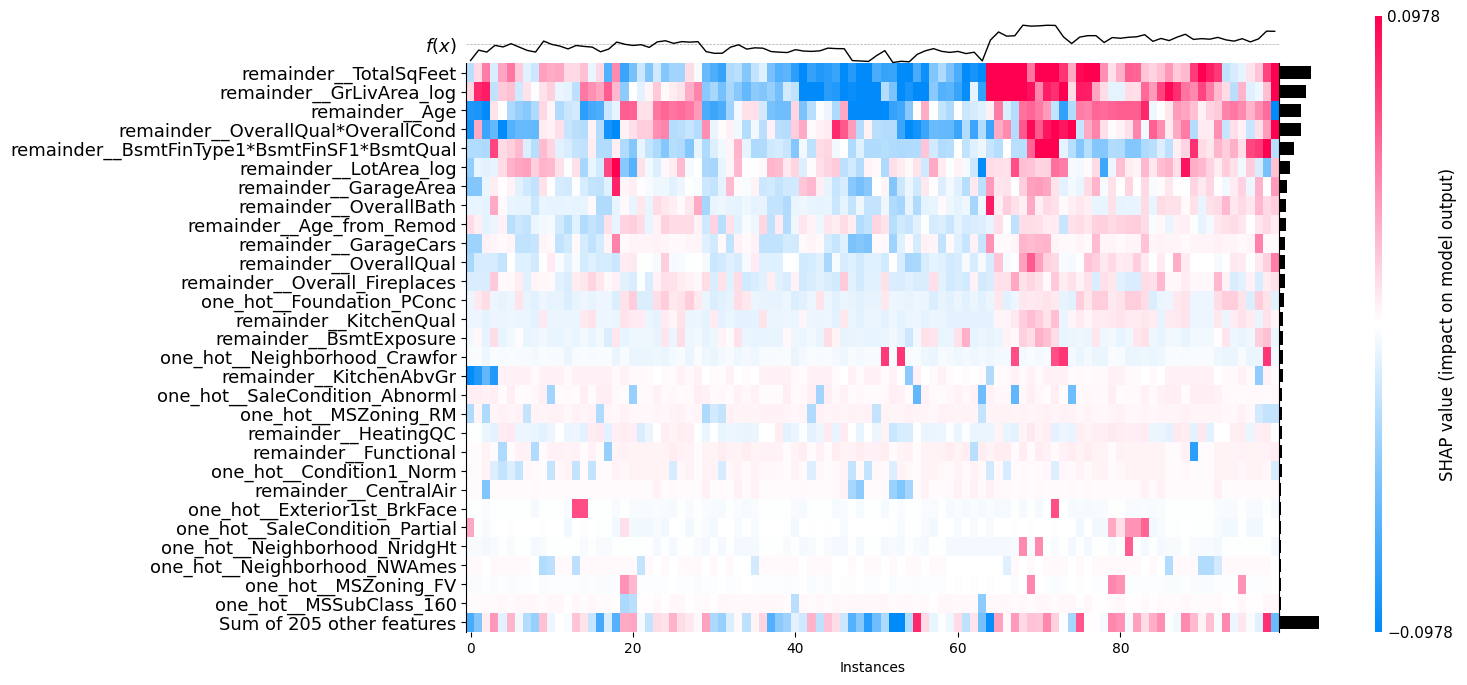

In [29]:
lasso_shap = run_shap(X_train, lasso_results, mode="linear", logger=logger)

Для лассо основными признаками стали те же что я и для риджа, тут отбор признаков происходит автоматически

## DNN

In [ ]:
dnn_pipeline = {
    "dnn": {
        "pipeline": Pipeline(
            [
                ("feature_transform", FeatureTransformer()),
                ("encoder", DNN_encoder()),
                ("model", MyModel()),
            ]
        ),
        "parameters": {
            # Данные
            "model__cat_cols": [FeatureTransformer.cat_cols],
            "model__num_cols": [FeatureTransformer.num_cols],
            # Обучение
            "model__epochs": [1000],
            "model__device": [Config.device],
            # Архитектура
            "model__emb_dim": [24],
            "model__inner_n": [256],
            "model__drop_n": [0.2],
            "model__n_layers": [1],
            "model__use_batchnorm": [True],
            # Loss
            "model__loss_reg": [RMSELoss],  # RMSELoss
            # Regularization
            "model__l1_lambda": [0.023081011668103977],
            # Optimizer
            "model__optim": [torch.optim.Adam],
            "model__optim_lr": [0.06343656703028737],
            # Scheduler
            "model__scheduler": [torch.optim.lr_scheduler.ReduceLROnPlateau],
            "model__lr_scheduler": [True],
            "model__factor": [0.09023739101987314],
            "model__patience": [20],  # 15,20
            "model__threshold": [0.1],
            "model__min_lr": [1e-10],
            # Early Stopping
            "model__early_stopping_patience": [45],  # 45
            "model__early_stopping_threshold": [0.001],
            # DataLoader
            "model__batch_size": [64],
            # Checkpoint
            "model__saving_threshold": [0.001],
            "model__save_path": ["checkpoints"],
        },
        "search_type": "grid",
        "fit_param": {
            "model__callbacks": [CheckpointManager(), EarlyStopping()]
        },  # ,MLflow_logger()
        "n_iter": 1,  # для рандом серча
        "plot_param": "model__optim_lr",
        "heatmap_params": ("model__optim_lr", "model__n_layers"),
        "shap_mode": "dnn",
        "cv": 5,
        "n_jobs": -1,
    }
}

Начинаем обучение 1 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Обучение остановлено на эпохе 204


Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Обучение остановлено на эпохе 143


... (2 outputs left out)

Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Обучение остановлено на эпохе 214


Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Обучение остановлено на эпохе 211
Best OOF 0.1311663896235491, best mean val RMSE 0.12759608439097053, best_val_std 0.03018646428243801
Best searched params
model__batch_size                                                                  32
model__device                                                                    cuda
model__drop_n                                                                     0.2
model__early_stopping_patience                                                     45
model__early_stopping_threshold                                                 0.001
model__emb_dim                                                                     24
model__epochs                                                                    1000
model__factor                                                                0.090237
model__inner_n                                                                    256
model__l1_lambda                                                     

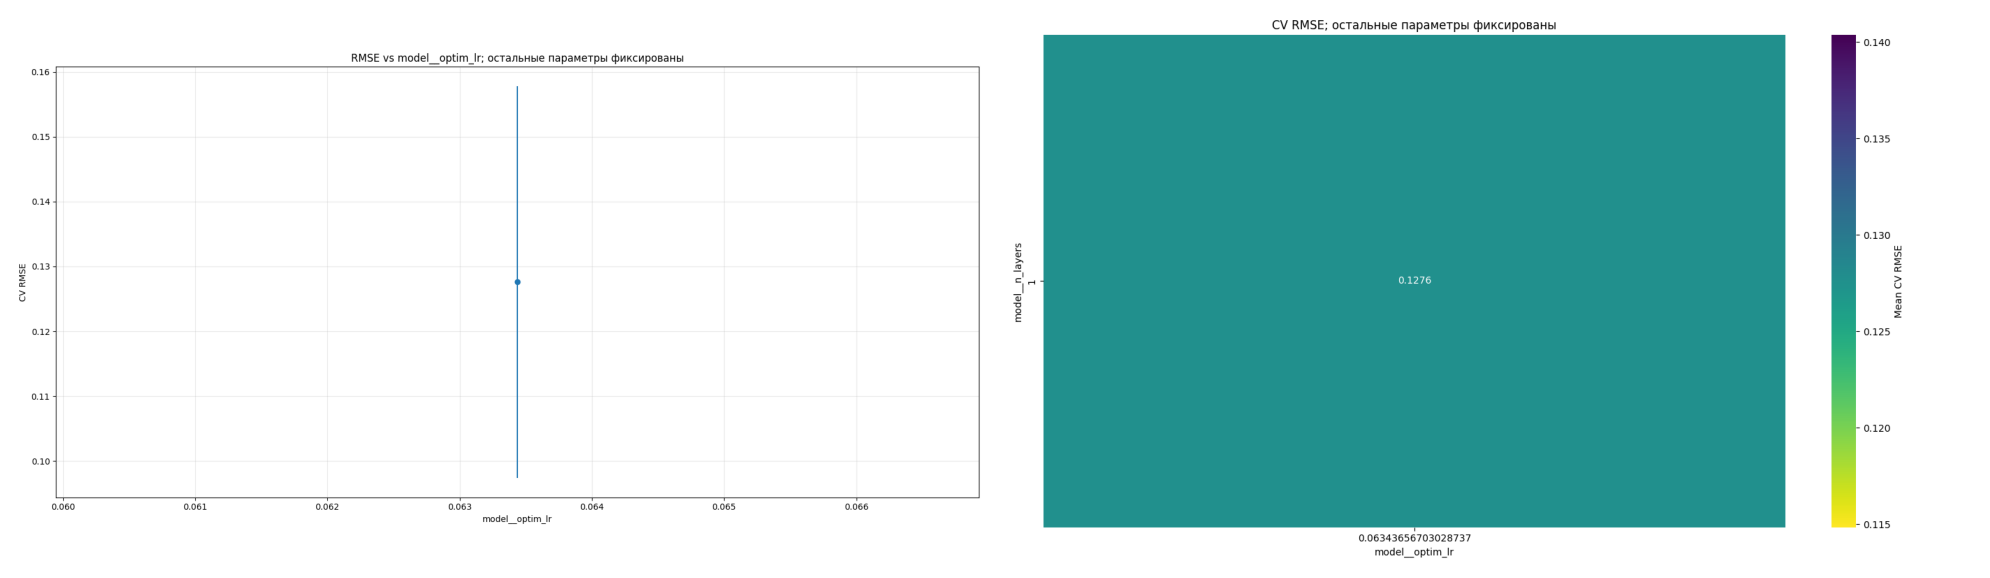

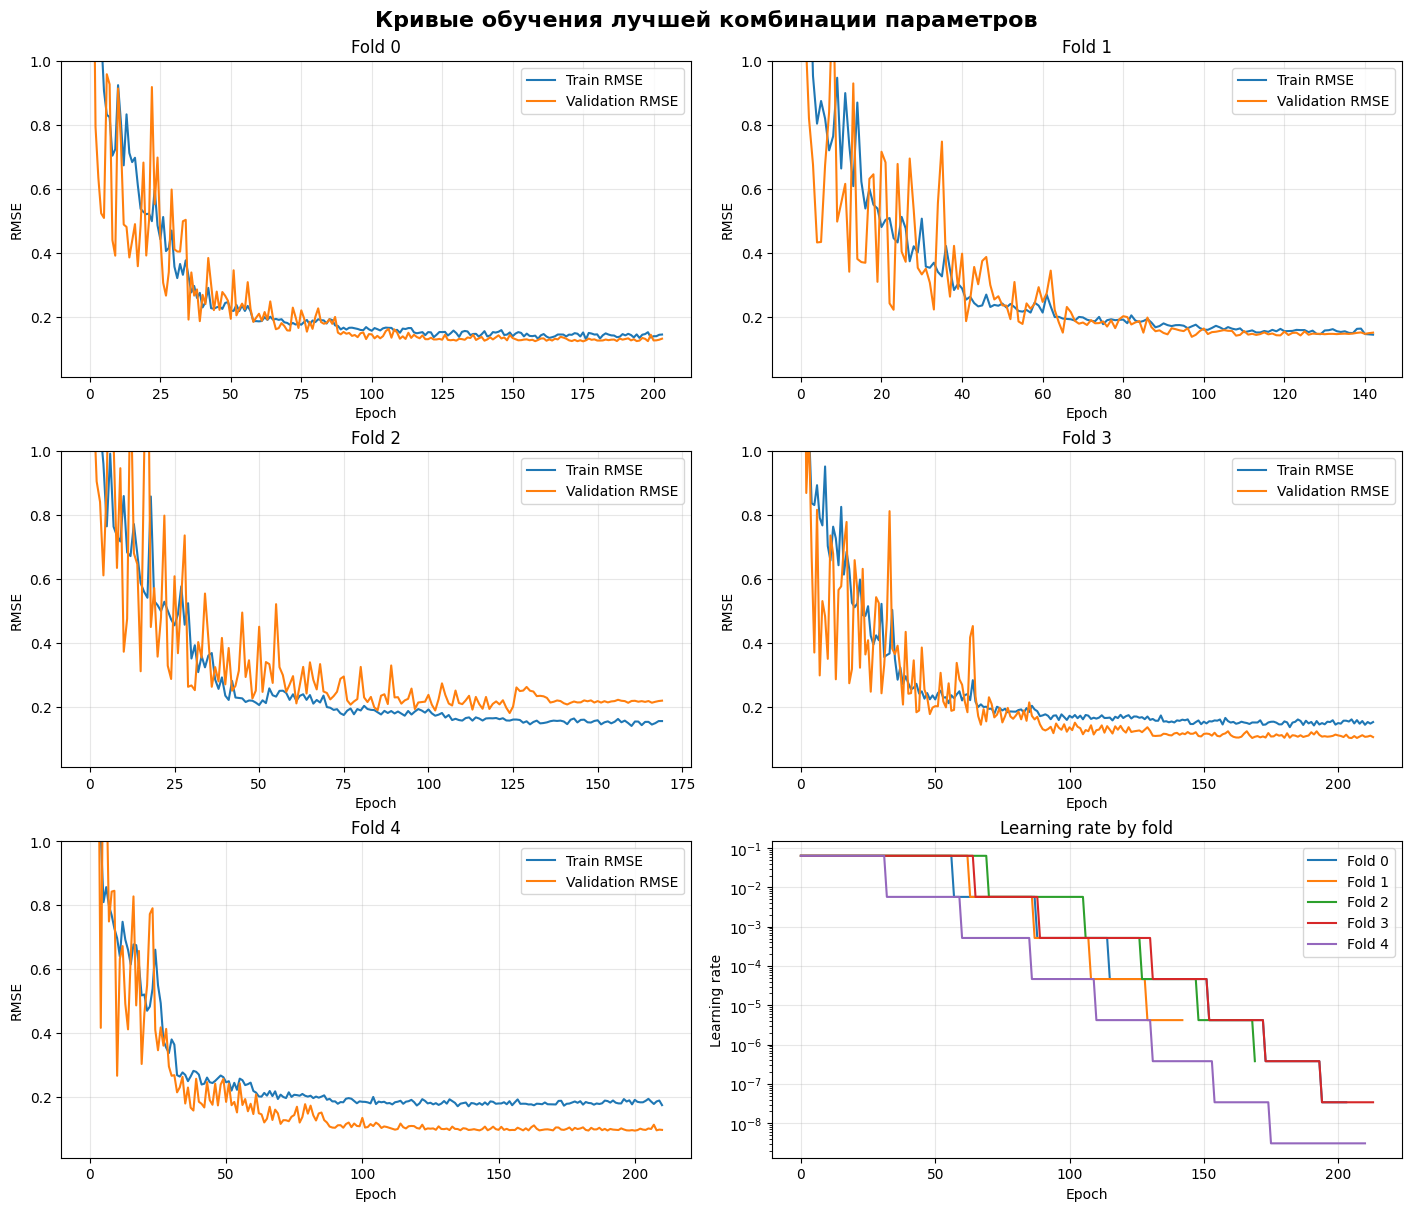

In [54]:
dnn_results = run_experiment(X_train, y_train, "dnn", dnn_pipeline, logger)
ModelSaver.save_ensemble(dnn_results["best_ensemble"], "dnn")

Почти на всех фолдах модель сошлась кромме второго фолда, и шедулер на не дошел до минимума, я многое попробовал и сокращать patienece шедулера, все равно не сошлось на это фолде, возможно там какие то экстремально сложные примеры, лучше получилось сойтись использую маленькие батчи, возможно потому что делаю много маленьких шагов модель успевает побольше обучиться, что положительно сказыватеся на шагах шедулера,

### Optuna

In [24]:
def suggest_dnn_params(trial):
    return {
        "model__emb_dim": trial.suggest_categorical("model__emb_dim", [12, 24]),
        "model__drop_n": trial.suggest_categorical("model__drop_n", [0.1, 0.2]),
        "model__n_layers": trial.suggest_categorical("model__n_layers", [1, 2, 3, 4]),
        "model__inner_n": trial.suggest_categorical(
            "model__inner_n", [64, 128, 256, 512]
        ),
        "model__use_batchnorm": trial.suggest_categorical(
            "model__use_batchnorm", [True, False]
        ),
        "model__l1_lambda": trial.suggest_float(
            "model__l1_lambda",
            0.001,
            20,
            log=True,
        ),
        "model__optim_lr": trial.suggest_float("model__optim_lr", 0.00001, 0.1),
        "model__use_batchnorm": trial.suggest_categorical(
            "model__use_batchnorm", [True, False]
        ),
        # Scheduler
        "model__factor": trial.suggest_float("model__factor", 0.01, 0.1),
        "model__patience": trial.suggest_categorical(
            "model__patience", [5, 10, 15, 20]
        ),
        "model__threshold": trial.suggest_categorical(
            "model__threshold", [0.001, 0.01, 0.1]
        ),
        "model__min_lr": trial.suggest_categorical("model__min_lr", [1e-10]),
        # Early Stopping
        "model__early_stopping_patience": trial.suggest_categorical(
            "model__early_stopping_patience", [20, 30, 35, 45]
        ),
        "model__early_stopping_threshold": trial.suggest_categorical(
            "model__early_stopping_threshold", [0.01, 0.001, 0.0001]
        ),
        # DataLoader
        "model__batch_size": trial.suggest_categorical(
            "model__batch_size", [64, 128, 256, 512]
        ),
        # Checkpoint
        "model__saving_threshold": trial.suggest_categorical(
            "model__saving_threshold", [0.001]
        ),
    }


dnn_optuna_pipeline = {
    "dnn_optuna": {
        "pipeline": Pipeline(
            [
                ("feature_transform", FeatureTransformer()),
                ("encoder", DNN_encoder()),
                ("model", MyModel()),
            ]
        ),
        "parameters_to_search": suggest_dnn_params,
        "search_type": "grid",
        "fit_param": {"model__solver": "saga", "model__random_state": Config.seed},
        "search_type": "grid",
        "fit_param": {
            "model__callbacks": [CheckpointManager(), EarlyStopping()],
            "model__device": Config.device,
            "model__cat_cols": FeatureTransformer.cat_cols,
            "model__num_cols": FeatureTransformer.num_cols,
            "model__loss_reg": RMSELoss,  # Сделать RMSE losss
            "model__epochs": 1000,
            "model__optim": torch.optim.Adam,
            "model__scheduler": torch.optim.lr_scheduler.ReduceLROnPlateau,
            "model__lr_scheduler": True,
        },
        "n_iter": 150,  # для оптуны
        "plot_param": "model__optim_lr",
        "heatmap_params": ("model__inner_n", "model__n_layers"),
        "shap_mode": "dnn",
        "cv": 5,
        "n_jobs": -1,
    }
}

[I 2026-11-09 14:45:54,281] A new study created in memory with name: no-name-56da9de5-ad5f-4f31-a1c4-d49d2e1ba1e1


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Обучение остановлено на эпохе 74


Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Обучение остановлено на эпохе 51


... (1,792 outputs left out)

Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Обучение остановлено на эпохе 253


[I 2026-11-09 21:44:33,281] Trial 149 finished with value: 0.12967902754762886 and parameters: {'model__emb_dim': 24, 'model__drop_n': 0.2, 'model__n_layers': 1, 'model__inner_n': 256, 'model__use_batchnorm': True, 'model__l1_lambda': 0.03918038461413647, 'model__optim_lr': 0.09743875125218358, 'model__factor': 0.09526127231076618, 'model__patience': 20, 'model__threshold': 0.01, 'model__min_lr': 1e-10, 'model__early_stopping_patience': 45, 'model__early_stopping_threshold': 0.001, 'model__batch_size': 64, 'model__saving_threshold': 0.001}. Best is trial 73 with value: 0.12536399750075594.


Лучший скор: 0.12536399750075594
Лучшие параметры: {'model__emb_dim': 24, 'model__drop_n': 0.2, 'model__n_layers': 1, 'model__inner_n': 256, 'model__use_batchnorm': True, 'model__l1_lambda': 0.023081011668103977, 'model__optim_lr': 0.06343656703028737, 'model__factor': 0.09023739101987314, 'model__patience': 20, 'model__threshold': 0.01, 'model__min_lr': 1e-10, 'model__early_stopping_patience': 45, 'model__early_stopping_threshold': 0.001, 'model__batch_size': 64, 'model__saving_threshold': 0.001}
Best OOF 0.12536399750075594, best mean val RMSE 0.12303343468903724, best_val_std 0.023846875029489092
Best searched params
model__emb_dim                         24
model__drop_n                         0.2
model__n_layers                         1
model__inner_n                        256
model__use_batchnorm                 True
model__l1_lambda                 0.023081
model__optim_lr                  0.063437
model__factor                    0.090237
model__patience                     

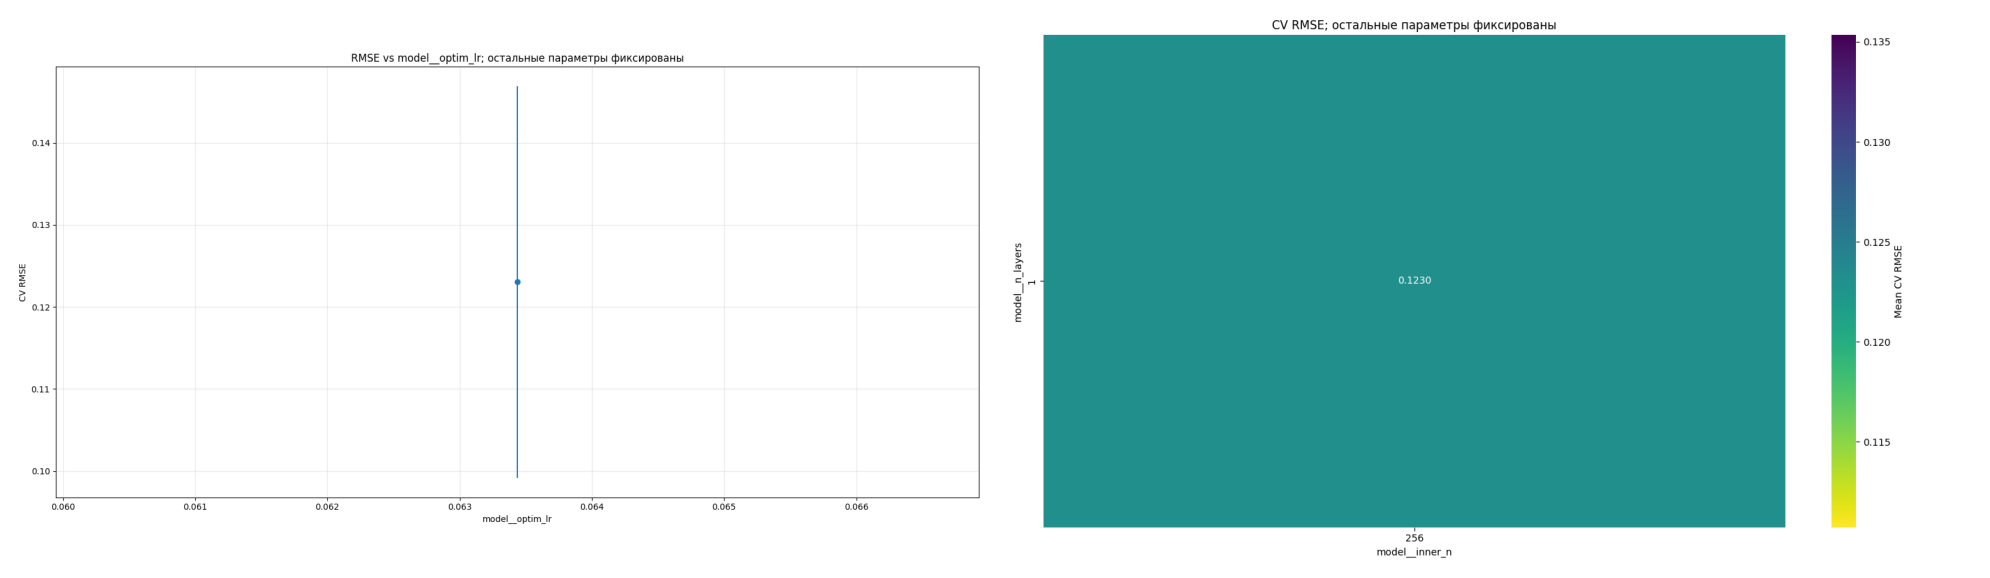

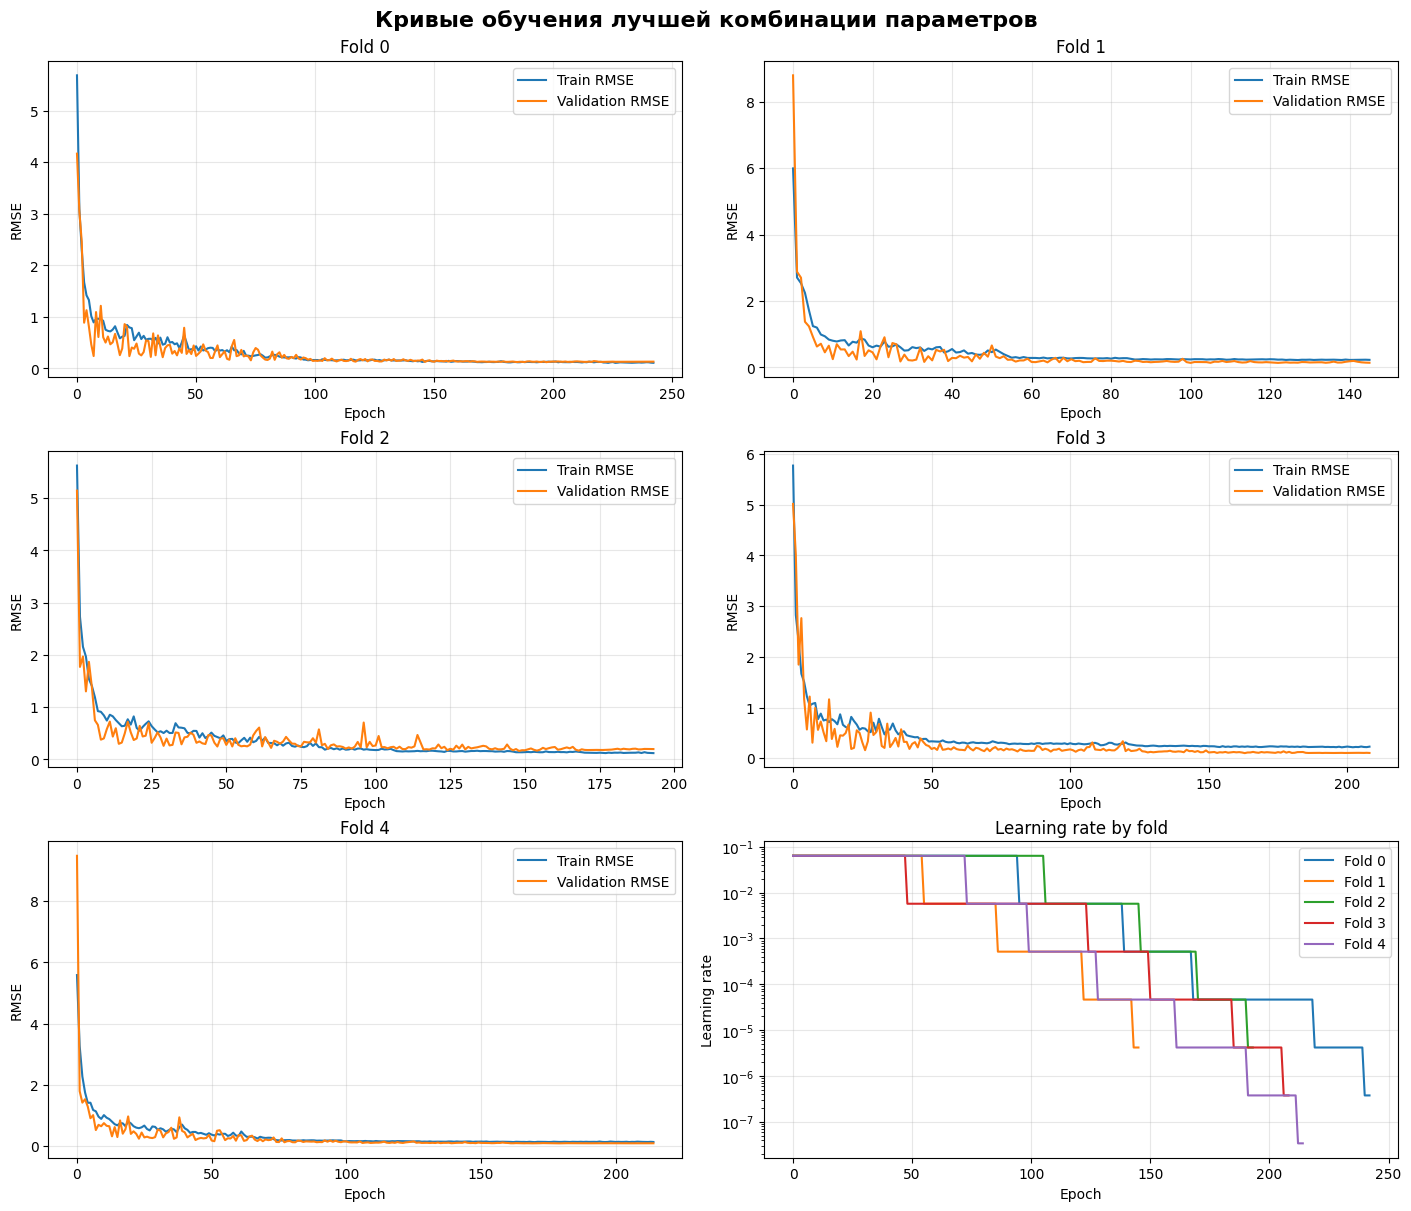

In [25]:
# return {
#     "run_id": model_run_id,
#     "results_df": results_df,
#     "best_value": best_value,
#     "best_ensemble": best_ensemble,
#     "best_results": best_results,
#     "best_history": best_history,
#     "figures": double_fig
# }
# Добавить функцию сохраненния обученного пайплайна

dnn_optuna_results = run_optuna_experiment(
    X_train, y_train, "dnn_optuna", dnn_optuna_pipeline, logger
)

In [27]:
dnn_optuna_results["best_results"]

{'best_oof_score': np.float64(0.12536399750075594),
 'best_mean_val_score': np.float64(0.12303343468903724),
 'best_val_std': np.float64(0.023846875029489092),
 'best_params': {'model__emb_dim': 24,
  'model__drop_n': 0.2,
  'model__n_layers': 1,
  'model__inner_n': 256,
  'model__use_batchnorm': True,
  'model__l1_lambda': 0.023081011668103977,
  'model__optim_lr': 0.06343656703028737,
  'model__factor': 0.09023739101987314,
  'model__patience': 20,
  'model__threshold': 0.01,
  'model__min_lr': 1e-10,
  'model__early_stopping_patience': 45,
  'model__early_stopping_threshold': 0.001,
  'model__batch_size': 64,
  'model__saving_threshold': 0.001},
 'best_cols': ['1stFlrSF',
  '1stFlrSF_log',
  '2ndFlrSF',
  '2ndFlrSF_log',
  '3SsnPorch',
  'Age',
  'Age_from_Remod',
  'Alley',
  'BedroomAbvGr',
  'BldgType',
  'BsmtExposure',
  'BsmtFin',
  'BsmtFinSF1',
  'BsmtFinSF1_log',
  'BsmtFinType1*BsmtFinSF1*BsmtQual',
  'BsmtFinType2*BsmtFinSF2*BsmtQual',
  'BsmtHalfBath',
  'BsmtQual',
  'B

### SHAP и отбор признаков

PermutationExplainer explainer: 235it [00:19,  9.38it/s]                         
PermutationExplainer explainer: 235it [00:12,  3.79it/s]                         
PermutationExplainer explainer: 235it [00:12,  3.89it/s]                         
PermutationExplainer explainer: 234it [00:12,  3.67it/s]                         
PermutationExplainer explainer: 234it [00:10,  1.05it/s]                         


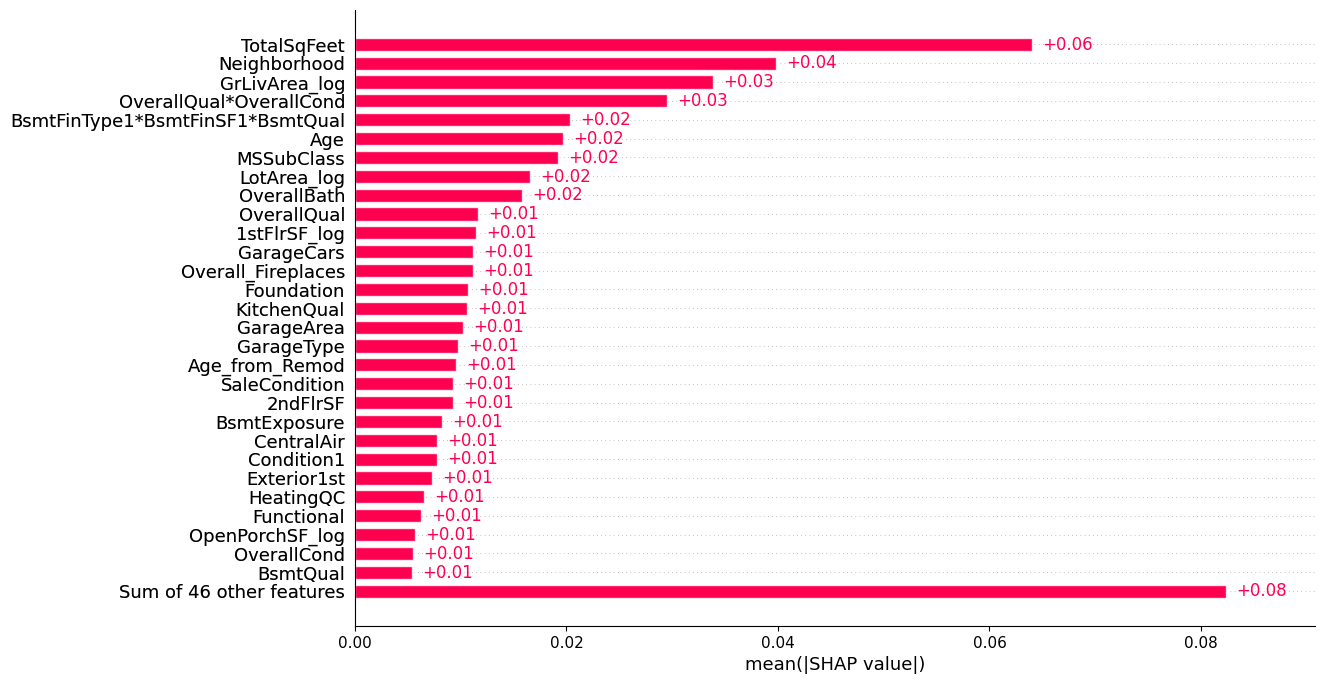

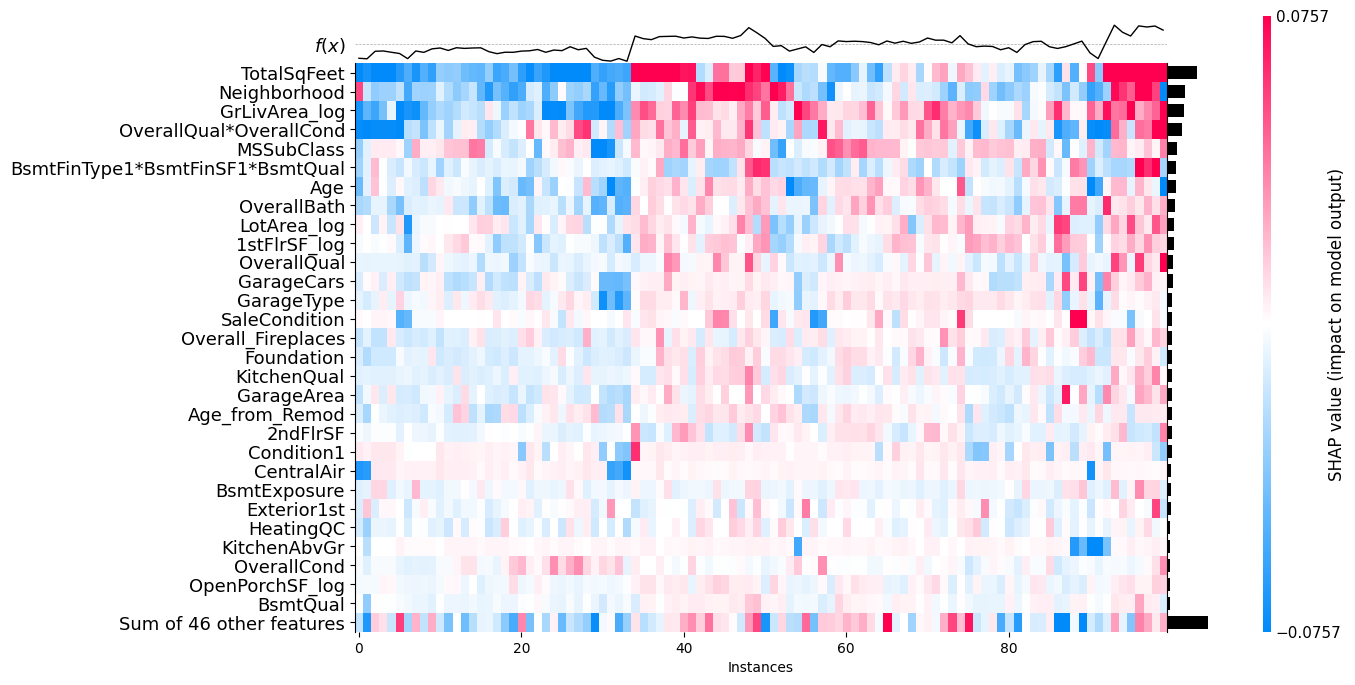

In [70]:
# return {
#     "importance": importance,
#     "oof_explanation": oof_explanation,
#     "figures": figures
# }

dnn_optuna_shap = run_shap(X_train, dnn_results, mode="dnn", logger=logger)

Для нейросети в наиболее имформативны в целом такие же признаки как и для линейных моделей, но в топе так же признак Neigborhood, так как из за слоя эмбедингов получилось его более информативно представить нежели ван-хотом

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

... (82 outputs left out)

Обучение остановлено на эпохе 213


Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Обучение остановлено на эпохе 226
Обучение остановлено на эпохе 147
Best OOF: 0.12803073743958035, best mean val RMSE: 0.12567741744222732, best val std: 0.024218630552293122, best feature amount: 68
-----Best searched params-----
model__batch_size                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       32
model__cat_cols       

,params,off_score,mean_val_score,std_val_score,feature_count,split0_val_score,split1_val_score,split2_val_score,split3_val_score,split4_val_score,...,param_model__num_cols,param_model__optim,param_model__optim_lr,param_model__patience,param_model__save_path,param_model__saving_threshold,param_model__scheduler,param_model__threshold,param_model__use_batchnorm,candidate_id
0,"{'model__batch_size': 32, 'model__cat_cols': [...",0.128031,0.125677,0.024219,68,0.123914,0.136212,0.165881,0.102424,0.099956,...,"[GrLivArea_log, FullBath, TotRmsAbvGrd, Garage...",<class 'torch.optim.adam.Adam'>,0.063437,20,checkpoints,0.001,<class 'torch.optim.lr_scheduler.ReduceLROnPla...,0.1,True,0
4,"{'model__batch_size': 32, 'model__cat_cols': [...",0.128731,0.125287,0.029376,40,0.117537,0.135145,0.176977,0.102777,0.094000,...,"[GrLivArea_log, FullBath, TotRmsAbvGrd, Garage...",<class 'torch.optim.adam.Adam'>,0.063437,20,checkpoints,0.001,<class 'torch.optim.lr_scheduler.ReduceLROnPla...,0.1,True,4
2,"{'model__batch_size': 32, 'model__cat_cols': [...",0.134344,0.129099,0.036969,54,0.118672,0.140137,0.194957,0.101186,0.090543,...,"[GrLivArea_log, FullBath, TotRmsAbvGrd, Garage...",<class 'torch.optim.adam.Adam'>,0.063437,20,checkpoints,0.001,<class 'torch.optim.lr_scheduler.ReduceLROnPla...,0.1,True,2
6,"{'model__batch_size': 32, 'model__cat_cols': [...",0.134800,0.130519,0.033495,26,0.121739,0.140700,0.190043,0.103894,0.096216,...,"[GrLivArea_log, FullBath, TotRmsAbvGrd, Garage...",<class 'torch.optim.adam.Adam'>,0.063437,20,checkpoints,0.001,<class 'torch.optim.lr_scheduler.ReduceLROnPla...,0.1,True,6
5,"{'model__batch_size': 32, 'model__cat_cols': [...",0.134807,0.130610,0.033169,33,0.121495,0.140686,0.189708,0.103748,0.097413,...,"[GrLivArea_log, FullBath, TotRmsAbvGrd, Garage...",<class 'torch.optim.adam.Adam'>,0.063437,20,checkpoints,0.001,<class 'torch.optim.lr_scheduler.ReduceLROnPla...,0.1,True,5
1,"{'model__batch_size': 32, 'model__cat_cols': [...",0.136522,0.131557,0.036276,61,0.122332,0.138724,0.197602,0.103698,0.095429,...,"[GrLivArea_log, FullBath, TotRmsAbvGrd, Garage...",<class 'torch.optim.adam.Adam'>,0.063437,20,checkpoints,0.001,<class 'torch.optim.lr_scheduler.ReduceLROnPla...,0.1,True,1
3,"{'model__batch_size': 32, 'model__cat_cols': [...",0.137048,0.131845,0.037206,47,0.119631,0.139083,0.200293,0.103298,0.096918,...,"[GrLivArea_log, FullBath, TotRmsAbvGrd, Garage...",<class 'torch.optim.adam.Adam'>,0.063437,20,checkpoints,0.001,<class 'torch.optim.lr_scheduler.ReduceLROnPla...,0.1,True,3
7,"{'model__batch_size': 32, 'model__cat_cols': [...",0.138971,0.134797,0.033613,19,0.119068,0.140714,0.197549,0.112033,0.104620,...,"[GrLivArea_log, FullBath, TotRmsAbvGrd, Garage...",<class 'torch.optim.adam.Adam'>,0.063437,20,checkpoints,0.001,<class 'torch.optim.lr_scheduler.ReduceLROnPla...,0.1,True,7
8,"{'model__batch_size': 32, 'model__cat_cols': [...",0.143156,0.139044,0.033859,12,0.126075,0.145082,0.201925,0.113104,0.109034,...,"[GrLivArea_log, FullBath, TotRmsAbvGrd, Garage...",<class 'torch.optim.adam.Adam'>,0.063437,20,checkpoints,0.001,<class 'torch.optim.lr_scheduler.ReduceLROnPla...,0.1,True,8


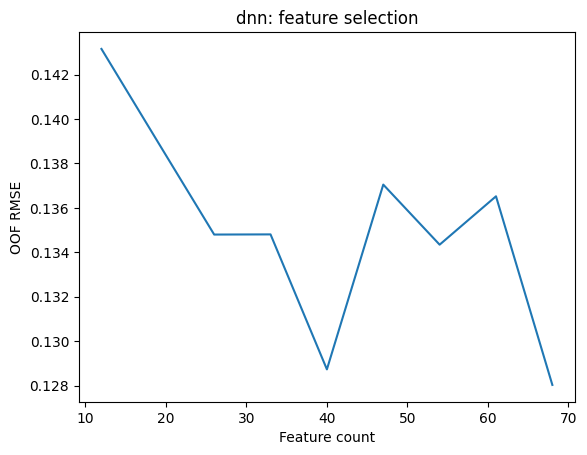

In [71]:
dnn_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=dnn_results["cv_folds"],
    importance=dnn_optuna_shap["importance"],
    search_results=dnn_results["best_results"],
    model_name="dnn",
    model_configs=dnn_pipeline,
    model_run_id=dnn_results["run_id"],
    logger=logger,
)

if dnn_fs_results["best_oof_score"] < dnn_results["best_results"]["best_oof_score"]:
    ModelSaver.save_ensemble(
        dnn_fs_results["best_ensemble"],
        "DNN",
        save_fs=dnn_fs_results["best_results"]["best_cols"],
    )
else:
    ModelSaver.save_ensemble(dnn_results["best_ensemble"], "DNN")

Очень неплохо прирост по скоре у нейросети, возможно часть фичей и правда ей мешала сойтись, плюс ограничение количество фичей приятно скажется на скорости обучения, поэтому в этом случае я сохраню это ограничение. P.S - отбор параметрво ухудшил результат, мне кажется на данном датасете это не лучшая практика

## Catboost

In [158]:
catboost_pipeline = {
    "catboost": {
        "pipeline": Pipeline(
            [
                ("feature_transform", FeatureTransformer(cat_boosting=True)),
                ("model", CatBoostRegressor(allow_writing_files=False)),
            ]
        ),
        "parameters": {
            "model__boosting_type": ["Plain"],  # ["Plain", "Ordered"]
            "model__iterations": [1000],  # np.linspace(1, 100, 5, dtype=int)
            "model__learning_rate": [0.05211448378065621],  # [0.08]
            "model__depth": [4],  # [4, 5, 6, 8]
            "model__bootstrap_type": ["Bernoulli"],
            "model__thread_count": [-1],
            "model__l2_leaf_reg": [0.01727277227745447],  # np.float64(0.0098)
            "model__rsm": [1.0],  # [0.6, 0.8, 1.0]
            "model__subsample": [0.8],
            "model__border_count": [256],
            "model__min_data_in_leaf": [50],
            "model__max_ctr_complexity": [2],
            "model__one_hot_max_size": [6],
            "model__eval_metric": ["RMSE"],
            "model__loss_function": ["RMSE"],
            "model__random_strength": [1.7444045228543141],  # [0, 0.5, 1, 2]
            "model__verbose": [False],
            "model__random_seed": [Config.seed],
            "model__early_stopping_rounds": [50],
        },
        "fit_param": {"model__cat_features": FeatureTransformer.cat_cols},
        "n_iter": 1,
        "plot_param": "model__learning_rate",
        "heatmap_params": ("model__learning_rate", "model__l2_leaf_reg"),
        "shap_mode": "catboost",
        "cv": 5,
        "n_jobs": -1,
    }
}

Начинаем обучение 1 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF 0.12294296693761307, best mean val RMSE 0.12147103110370491, best_val_std 0.018745635685902835
Best searched params
model__boosting_type              Plain
model__bootstrap_type         Bernoulli
model__border_count                 256
model__depth                          4
model__early_stopping_rounds         50
model__eval_metric                 RMSE
model__iterations                  1000
model__l2_leaf_reg             0.017273
model__learning_rate           0.052114
model__loss_function               RMSE
model__max_ctr_complexity             2
model__min_data_in_leaf              50
model__one_hot_max_size               6
model__random_seed                   42
model__random_strength         1.744405
model__rsm                          1.0
model__subsample                    0.8
model__thread_count                  -1
model__verbose                    False


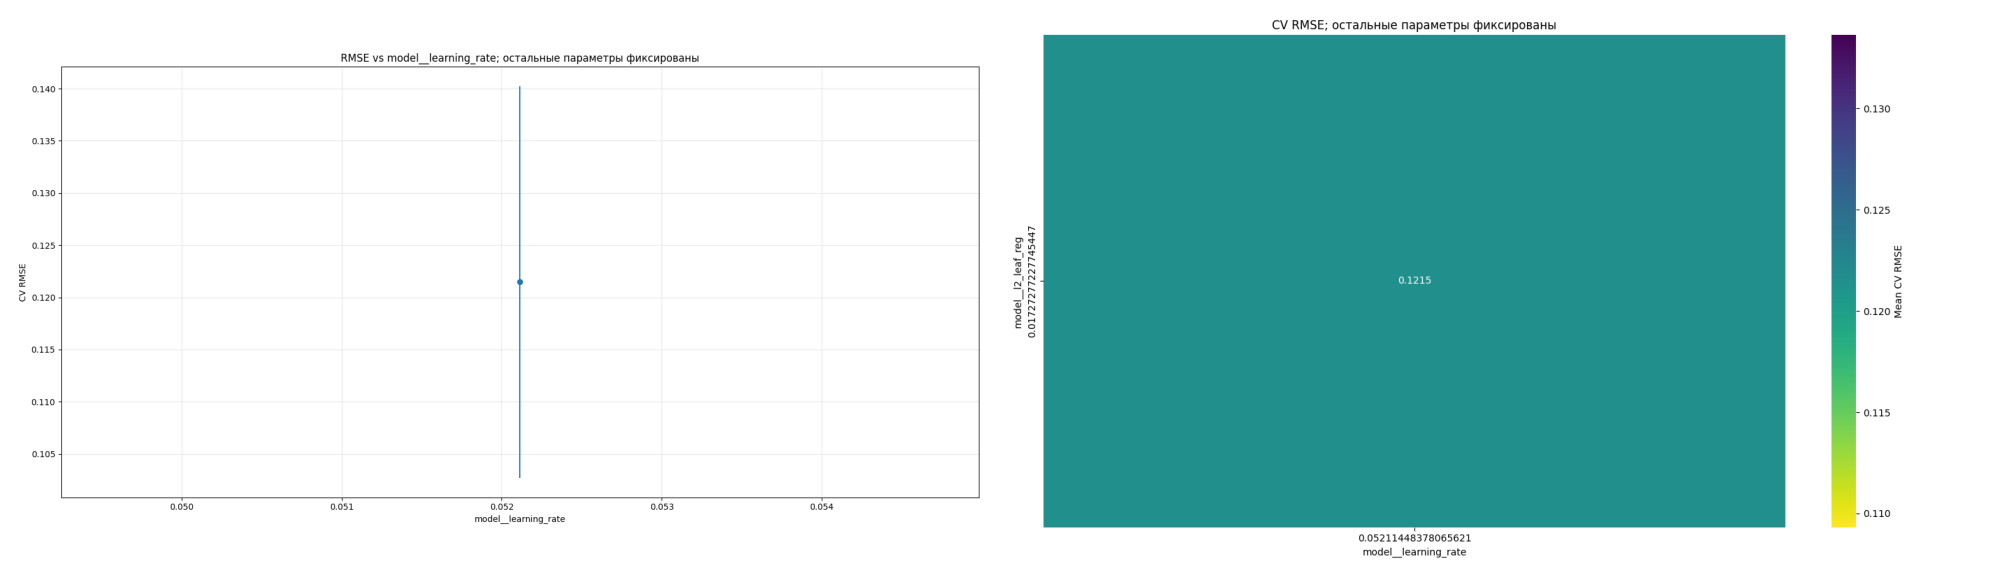

In [159]:
catboost_results = run_experiment(
    X_train, y_train, "catboost", catboost_pipeline, logger
)
ModelSaver.save_ensemble(catboost_results["best_ensemble"], "catboost")

### Optuna

In [ ]:
def suggest_catboost_params(trial):
    return {
        "model__boosting_type": trial.suggest_categorical(
            "model__boosting_type", ["Plain"]
        ),
        "model__iterations": trial.suggest_categorical("model__iterations", [1000]),
        "model__learning_rate": trial.suggest_float(
            "model__learning_rate",
            0.001,
            0.10,
            log=True,
        ),
        "model__depth": trial.suggest_categorical("model__depth", [4, 5, 6, 8]),
        "model__l2_leaf_reg": trial.suggest_float(
            "model__l2_leaf_reg",
            0.001,
            0.10,
            log=True,
        ),
        "model__subsample": trial.suggest_categorical(
            "model__subsample", [0.6, 0.8, 0.1]
        ),
        "model__border_count": trial.suggest_categorical(
            "model__border_count", [32, 64, 128, 256]
        ),
        "model__min_data_in_leaf": trial.suggest_categorical(
            "model__min_data_in_leaf", [30, 35, 45, 50]
        ),
        "model__max_ctr_complexity": trial.suggest_categorical(
            "model__max_ctr_complexity", [1, 2, 3, 4]
        ),
        "model__one_hot_max_size": trial.suggest_categorical(
            "model__one_hot_max_size", [4, 5, 6]
        ),
        "model__random_strength": trial.suggest_float(
            "model__random_strength", 1e-3, 10.0, log=True
        ),
        "model__early_stopping_rounds": trial.suggest_categorical(
            "model__early_stopping_rounds", [25, 35, 50]
        ),
    }


catboost_optuna_pipeline = {
    "catboost_optuna": {
        "pipeline": Pipeline(
            [
                ("feature_transform", FeatureTransformer(cat_boosting=True)),
                ("model", CatBoostRegressor(allow_writing_files=False)),
            ]
        ),
        "parameters_to_search": suggest_catboost_params,
        "search_type": "grid",
        "fit_param": {
            "model__random_seed": Config.seed,
            "model__cat_features": FeatureTransformer.cat_cols,
            "model__thread_count": -1,
            "model__rsm": 1.0,
            "model__bootstrap_type": "Bernoulli",
            "model__eval_metric": "RMSE",
            "model__loss_function": "RMSE",
            "model__verbose": False,
        },
        "n_iter": 500,  # для оптуны
        "plot_param": "model__learning_rate",
        "heatmap_params": ("model__learning_rate", "model__l2_leaf_reg"),
        "shap_mode": "catboost",
        "cv": 5,
        "n_jobs": 1,
    }
}

In [ ]:
catboost_optuna_results = run_optuna_experiment(
    X_train, y_train, "catboost_optuna", catboost_optuna_pipeline, logger
)

### SHAP и отбор признаков

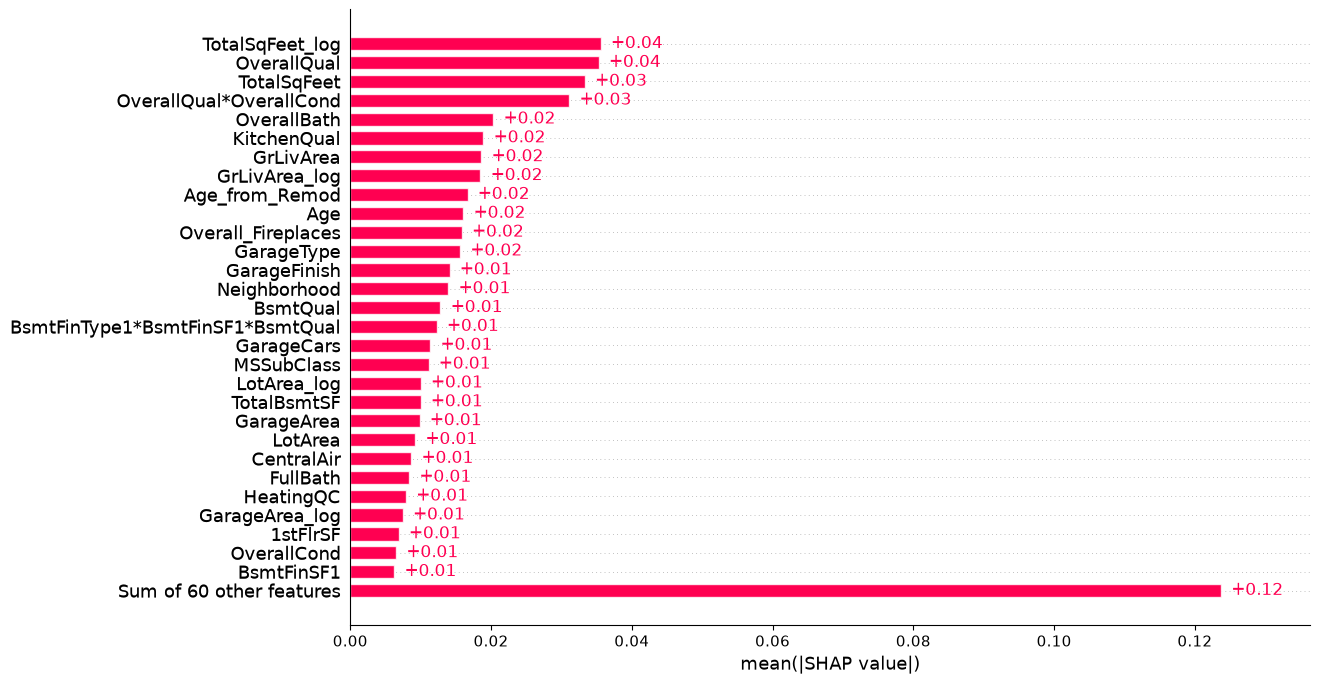

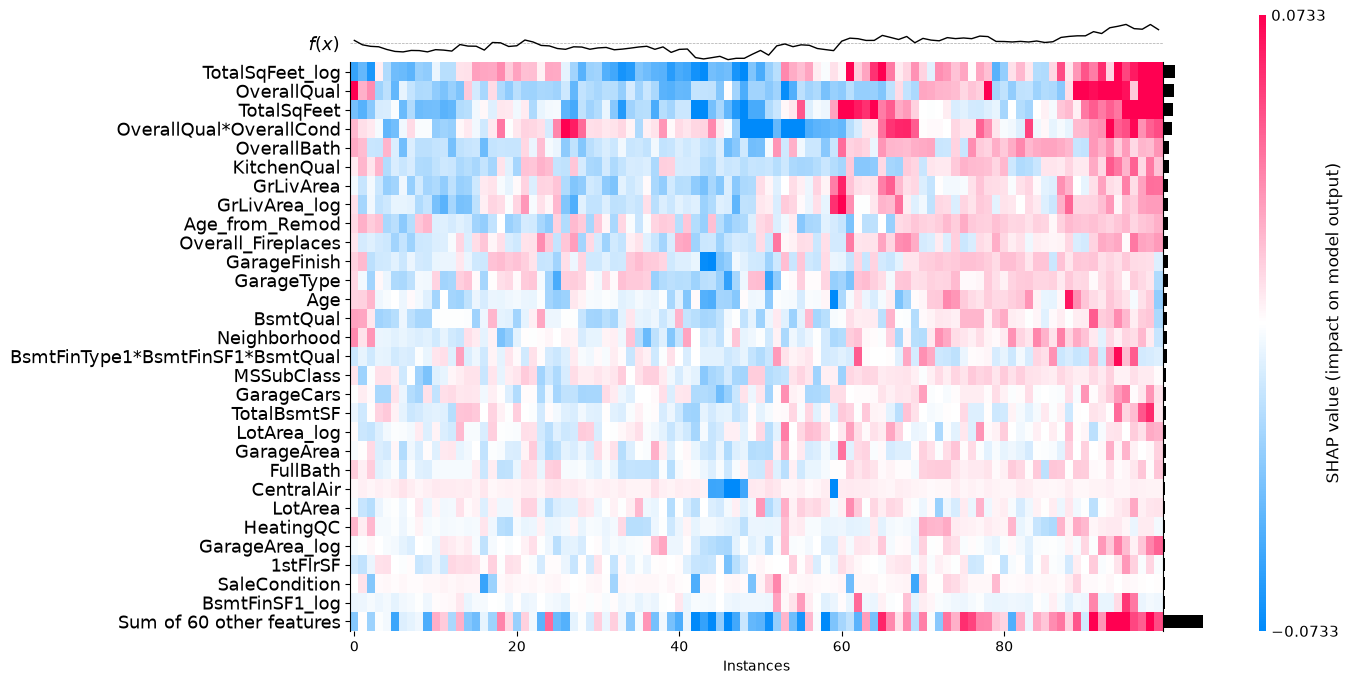

In [70]:
catboost_shap = run_shap(X_train, catboost_results, mode="catboost", logger=logger)

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF: 0.12287658782035721, best mean val RMSE: 0.12159199763358845, best val std: 0.01749552367862457, best feature amount: 33
-----Best searched params-----
model__boosting_type              Plain
model__bootstrap_type         Bernoulli
model__border_count                 256
model__depth                          4
model__early_stopping_rounds         50
model__eval_metric                 RMSE
model__iterations                  1000
model__l2_leaf_reg             0.017273
model__learning_rate           0.052114
model__loss_function               RMSE
model__max_ctr_complexity             2
model__min_data_in_leaf              50
model__one_hot_max_size               6
model__random_seed                   42
model__random_strength         1.744405
model__rsm                          1.0
model__subsample                    0.8
model__thread_count                  -1
model__verbose                    False


,params,off_score,mean_val_score,std_val_score,feature_count,split0_val_score,split1_val_score,split2_val_score,split3_val_score,split4_val_score,...,param_model__max_ctr_complexity,param_model__min_data_in_leaf,param_model__one_hot_max_size,param_model__random_seed,param_model__random_strength,param_model__rsm,param_model__subsample,param_model__thread_count,param_model__verbose,candidate_id
6,"{'model__boosting_type': 'Plain', 'model__boot...",0.122877,0.121592,0.017496,33,0.123402,0.133824,0.146353,0.104603,0.099778,...,2,50,6,42,1.744405,1.0,0.8,-1,False,6
0,"{'model__boosting_type': 'Plain', 'model__boot...",0.122912,0.121138,0.020588,81,0.122504,0.131874,0.153045,0.101930,0.096337,...,2,50,6,42,1.744405,1.0,0.8,-1,False,0
1,"{'model__boosting_type': 'Plain', 'model__boot...",0.123517,0.122100,0.018430,73,0.123895,0.137102,0.146227,0.106665,0.096610,...,2,50,6,42,1.744405,1.0,0.8,-1,False,1
3,"{'model__boosting_type': 'Plain', 'model__boot...",0.124191,0.122593,0.019635,57,0.123280,0.134523,0.152226,0.104140,0.098797,...,2,50,6,42,1.744405,1.0,0.8,-1,False,3
2,"{'model__boosting_type': 'Plain', 'model__boot...",0.124283,0.122448,0.021058,65,0.122743,0.136689,0.153523,0.101699,0.097584,...,2,50,6,42,1.744405,1.0,0.8,-1,False,2
4,"{'model__boosting_type': 'Plain', 'model__boot...",0.124965,0.123104,0.021268,49,0.121651,0.136968,0.155288,0.105114,0.096499,...,2,50,6,42,1.744405,1.0,0.8,-1,False,4
5,"{'model__boosting_type': 'Plain', 'model__boot...",0.125061,0.123290,0.020748,41,0.123261,0.137725,0.153836,0.101410,0.100217,...,2,50,6,42,1.744405,1.0,0.8,-1,False,5
7,"{'model__boosting_type': 'Plain', 'model__boot...",0.125922,0.124850,0.016167,25,0.126140,0.136747,0.147456,0.109405,0.104500,...,2,50,6,42,1.744405,1.0,0.8,-1,False,7
8,"{'model__boosting_type': 'Plain', 'model__boot...",0.126951,0.125753,0.017159,17,0.129370,0.141786,0.145777,0.108561,0.103271,...,2,50,6,42,1.744405,1.0,0.8,-1,False,8


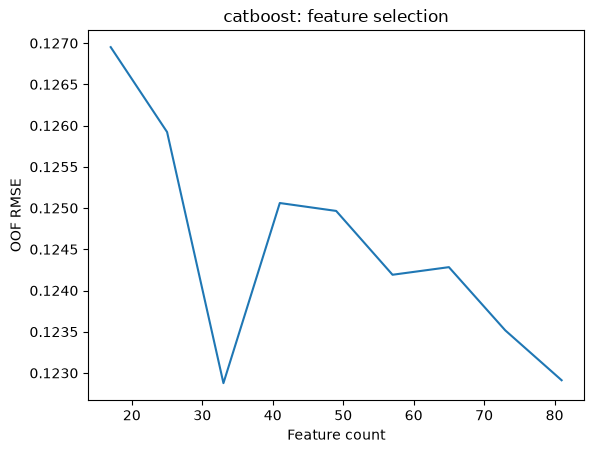

In [111]:
catboost_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=catboost_results["cv_folds"],
    importance=catboost_shap["importance"],
    search_results=catboost_results["best_results"],
    model_name="catboost",
    model_configs=catboost_pipeline,
    model_run_id=catboost_results["run_id"],
    logger=logger,
)

if (
    catboost_fs_results["best_oof_score"]
    < catboost_results["best_results"]["best_oof_score"]
):
    ModelSaver.save_ensemble(
        catboost_fs_results["best_ensemble"],
        "catboost",
        save_fs=catboost_fs_results["best_results"]["best_cols"],
    )
else:
    ModelSaver.save_ensemble(catboost_results["best_ensemble"], "catboost")

Я решил отказаться от отбора признаков ШАПОМ, так как мне не понравился приличный gap между холд-аут и CV, повторюсь так как я все отбираю по валидации, то я на нее постепенно оверфитаюсь, поэтому я решил сократить объем использования валидации для принятия решений

## LightGBM

In [160]:
lightgbm_pipeline = {
    "lightgbm": {
        "pipeline": Pipeline(
            [
                ("feature_transform", FeatureTransformer(cat_boosting=True)),
                ("model", LGBMRegressor()),
            ]
        ),
        "parameters": {
            "model__device": ["cpu"],
            "model__boosting_type": ["gbdt"],
            "model__n_estimators": [2000],  # np.linspace(1, 100, 5, dtype=int)
            "model__learning_rate": [
                0.098
            ],  # np.linspace(0.01, 0.1, 5); [np.float64(0.0775)]
            "model__max_depth": [4],  # [4, 5, 6, 8]
            "model__subsample": [0.4],  # [0.6, 0.8, 1.0]
            "model__colsample_bytree": [0.8],  # [0.6, 0.8, 1.0]
            "model__reg_alpha": [0.008],  # [0.1, 0.2, 0.4, 0.5, 1]
            "model__reg_lambda": [0.04000000000000001],  # [0.01, 0.1, 0.5, 5, 10]
            "model__objective": ["regression"],
            "model__metric": ["rmse"],
            "model__min_child_samples": [40],
            "model__min_child_weight": [1],  # np.linspace(1, 5, 3, dtype=int)
            "model__min_split_gain": [0.0005],  # np.linspace(0.01, 0.1, 5)
            "model__n_jobs": [-1],
            "model__random_state": [Config.seed],
            "model__verbosity": [-1],
            "model__early_stopping_round": [30],
        },
        "fit_param": {},
        "n_iter": 1,
        "plot_param": "model__learning_rate",
        "heatmap_params": ("model__learning_rate", "model__max_depth"),
        "shap_mode": "lightgbm",
        "cv": 5,
        "n_jobs": 1,
    }
}

Начинаем обучение 1 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF 0.12585535135784565, best mean val RMSE 0.12470364913678486, best_val_std 0.016771964925190206
Best searched params
model__boosting_type               gbdt
model__colsample_bytree             0.8
model__device                       cpu
model__early_stopping_round          30
model__learning_rate              0.098
model__max_depth                      4
model__metric                      rmse
model__min_child_samples             40
model__min_child_weight               1
model__min_split_gain            0.0005
model__n_estimators                2000
model__n_jobs                        -1
model__objective             regression
model__random_state                  42
model__reg_alpha                  0.008
model__reg_lambda                  0.04
model__subsample                    0.4
model__verbosity                     -1


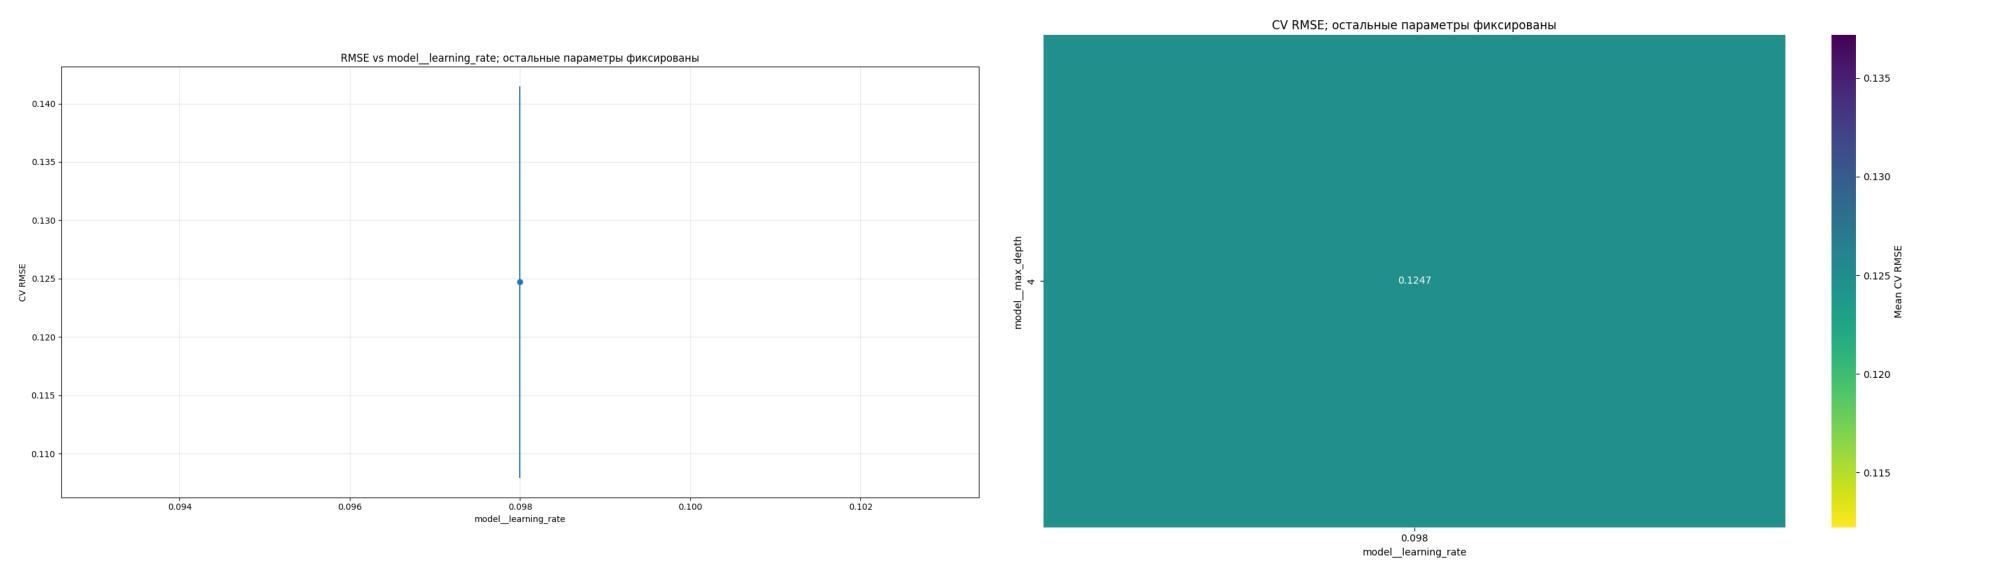

In [161]:
lightgbm_results = run_experiment(
    X_train, y_train, "lightgbm", lightgbm_pipeline, logger
)
ModelSaver.save_ensemble(lightgbm_results["best_ensemble"], "lightgbm")

### Optuna

In [ ]:
def suggest_lightgbm_params(trial):
    return {
        "model__boosting_type": trial.suggest_categorical(
            "model__boosting_type", ["gbdt", "dart"]
        ),
        "model__n_estimators": trial.suggest_categorical("model__n_estimators", [1000]),
        "model__learning_rate": trial.suggest_float(
            "model__learning_rate",
            0.001,
            0.10,
            log=True,
        ),
        "model__max_depth": trial.suggest_categorical(
            "model__max_depth", [4, 5, 6, 7, 8]
        ),
        "model__subsample": trial.suggest_categorical(
            "model__subsample", [0.4, 0.5, 0.6, 0.8, 1]
        ),
        "model__colsample_bytree": trial.suggest_categorical(
            "model__colsample_bytree", [0.4, 0.5, 0.6, 0.8, 1]
        ),
        "model__reg_alpha": trial.suggest_float(
            "model__reg_alpha",
            0.001,
            0.10,
            log=True,
        ),
        "model__reg_alpha": trial.suggest_float(
            "model__reg_alpha",
            0.001,
            0.10,
            log=True,
        ),
        "model__min_child_samples": trial.suggest_categorical(
            "model__min_child_samples", [35, 40, 45, 50, 55]
        ),
        "model__min_child_weight": trial.suggest_float(
            "model__min_child_weight",
            0.01,
            1,
            log=True,
        ),
        "model__min_split_gain": trial.suggest_float(
            "model__min_split_gain",
            0.0001,
            0.01,
            log=True,
        ),
        "model__early_stopping_round": trial.suggest_categorical(
            "model__early_stopping_round", [25, 30, 35, 40, 45, 50]
        ),
    }


lightgbm_optuna_pipeline = {
    "lightgbm_optuna": {
        "pipeline": Pipeline(
            [
                ("feature_transform", FeatureTransformer(cat_boosting=True)),
                ("model", LGBMRegressor(allow_writing_files=False)),
            ]
        ),
        "parameters_to_search": suggest_lightgbm_params,
        "search_type": "grid",
        "fit_param": {
            "model__random_seed": Config.seed,
            "model__cat_features": FeatureTransformer.cat_cols,
            "model__verbosity": -1,
            "model__n_jobs": -1,
            "model__device": "gpu",
            "model__objective": "regression",
            "model__metric": "rmse",
        },
        "n_iter": 500,  # для оптуны
        "plot_param": "model__learning_rate",
        "heatmap_params": ("model__learning_rate", "model__max_depth"),
        "shap_mode": "lightgbm",
        "cv": 5,
        "n_jobs": -1,
    }
}

In [ ]:
lightgbm_optuna_results = run_optuna_experiment(
    X_train, y_train, "lightgbm_optuna", lightgbm_optuna_pipeline, logger
)

### SHAP и отбор признаков

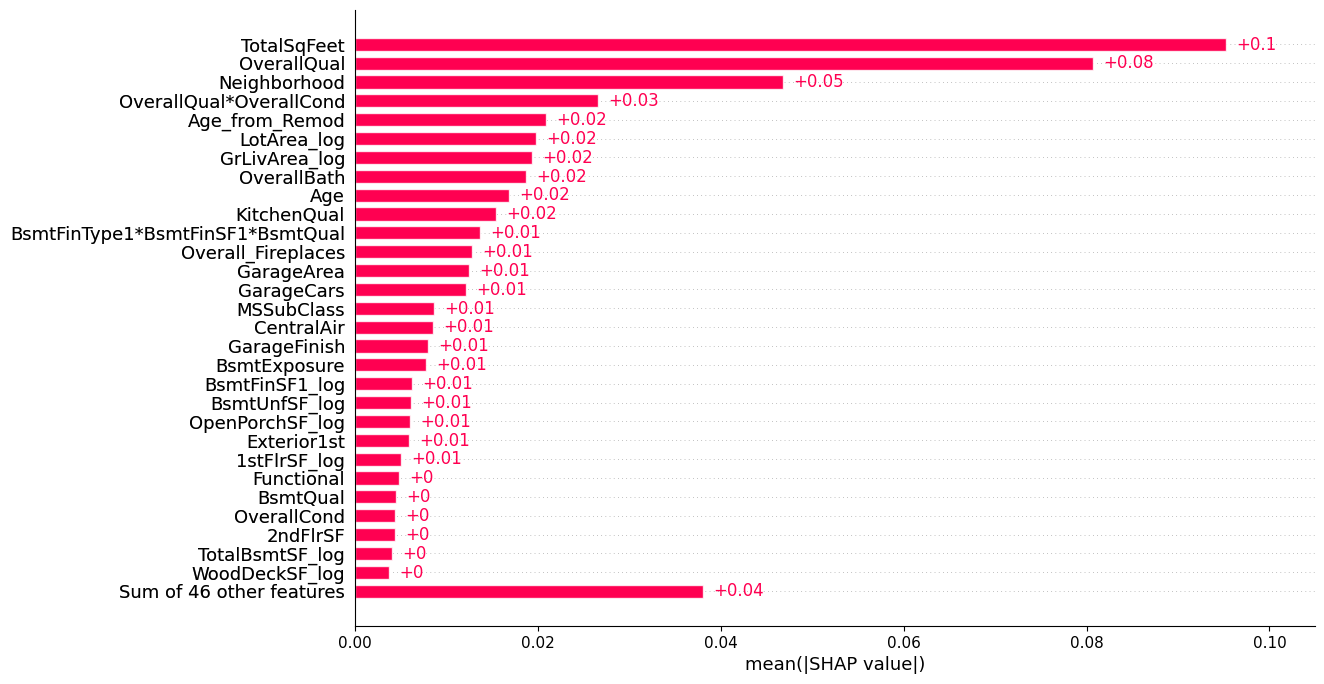

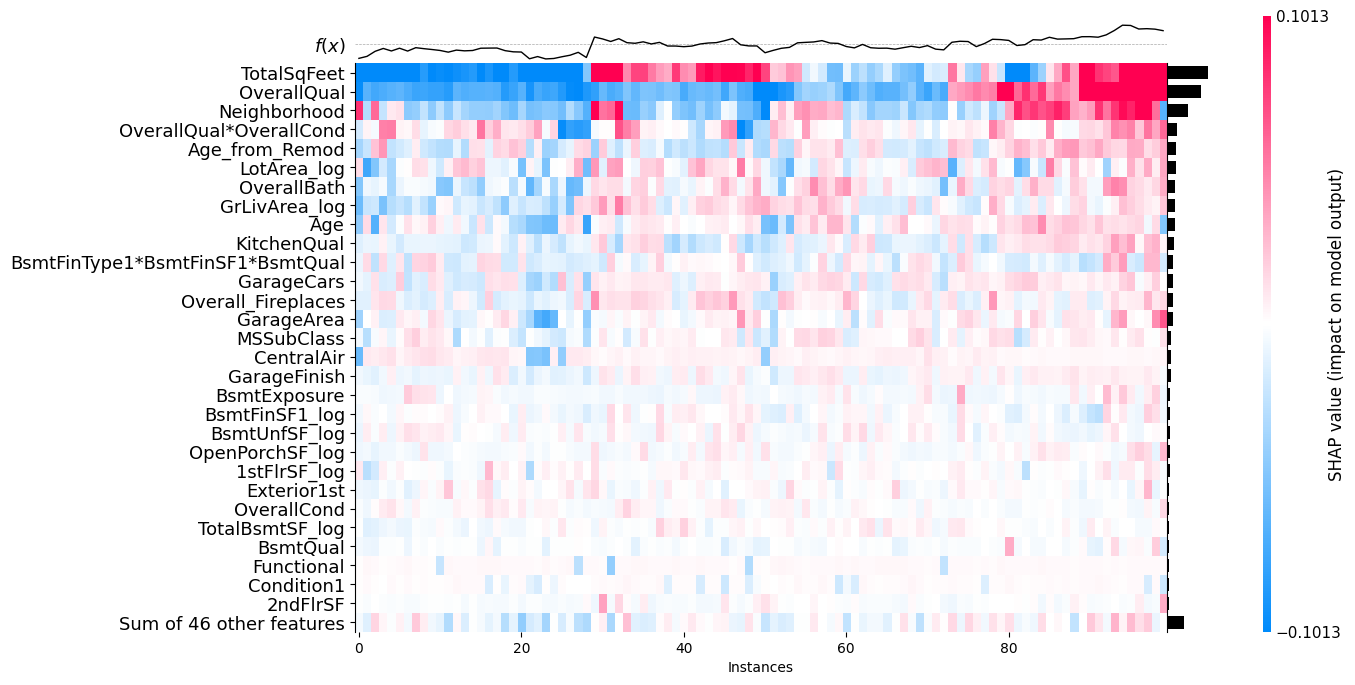

In [162]:
lightgbm_shap = run_shap(X_train, lightgbm_results, mode="lightgbm", logger=logger)

lightGBM очень сильно заострил внимание на обобщающих признаках, а так же из за обработки категориальных значений уделил большое внимание neigborhood 

Training:   0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mento

Training:   0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mento

Training:   0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mento

... (10 outputs left out)

Training:   0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mento

Best OOF: 0.12480425856041322, best mean val RMSE: 0.123316144363764, best val std: 0.018990680599274085, best feature amount: 81
-----Best searched params-----
model__boosting_type               gbdt
model__colsample_bytree             0.8
model__device                       cpu
model__early_stopping_round          30
model__learning_rate              0.098
model__max_depth                      4
model__metric                      rmse
model__min_child_samples             40
model__min_child_weight               1
model__min_split_gain            0.0005
model__n_estimators                2000
model__n_jobs                        -1
model__objective             regression
model__random_state                  42
model__reg_alpha                  0.008
model__reg_lambda                  0.04
model__subsample                    0.4
model__verbosity                     -1


,params,off_score,mean_val_score,std_val_score,feature_count,split0_val_score,split1_val_score,split2_val_score,split3_val_score,split4_val_score,...,param_model__min_split_gain,param_model__n_estimators,param_model__n_jobs,param_model__objective,param_model__random_state,param_model__reg_alpha,param_model__reg_lambda,param_model__subsample,param_model__verbosity,candidate_id
0,"{'model__boosting_type': 'gbdt', 'model__colsa...",0.124804,0.123316,0.018991,81,0.133124,0.125861,0.152209,0.105448,0.099939,...,0.0005,2000,-1,regression,42,0.008,0.04,0.4,-1,0
2,"{'model__boosting_type': 'gbdt', 'model__colsa...",0.125055,0.123779,0.017599,65,0.131018,0.125992,0.151690,0.107774,0.102422,...,0.0005,2000,-1,regression,42,0.008,0.04,0.4,-1,2
1,"{'model__boosting_type': 'gbdt', 'model__colsa...",0.125082,0.123729,0.018123,73,0.129940,0.127136,0.152604,0.107443,0.101524,...,0.0005,2000,-1,regression,42,0.008,0.04,0.4,-1,1
5,"{'model__boosting_type': 'gbdt', 'model__colsa...",0.125295,0.124008,0.017680,41,0.134359,0.127752,0.149194,0.108602,0.100133,...,0.0005,2000,-1,regression,42,0.008,0.04,0.4,-1,5
6,"{'model__boosting_type': 'gbdt', 'model__colsa...",0.125354,0.124198,0.016764,33,0.131449,0.126234,0.150684,0.108199,0.104424,...,0.0005,2000,-1,regression,42,0.008,0.04,0.4,-1,6
7,"{'model__boosting_type': 'gbdt', 'model__colsa...",0.126449,0.125187,0.017596,25,0.132989,0.127657,0.152675,0.108798,0.103813,...,0.0005,2000,-1,regression,42,0.008,0.04,0.4,-1,7
8,"{'model__boosting_type': 'gbdt', 'model__colsa...",0.126494,0.125234,0.017585,17,0.133394,0.126433,0.152980,0.109846,0.103518,...,0.0005,2000,-1,regression,42,0.008,0.04,0.4,-1,8
4,"{'model__boosting_type': 'gbdt', 'model__colsa...",0.126553,0.125227,0.018050,49,0.132095,0.125928,0.154950,0.107701,0.105460,...,0.0005,2000,-1,regression,42,0.008,0.04,0.4,-1,4
3,"{'model__boosting_type': 'gbdt', 'model__colsa...",0.126867,0.125673,0.017138,57,0.132595,0.127375,0.153209,0.109302,0.105885,...,0.0005,2000,-1,regression,42,0.008,0.04,0.4,-1,3


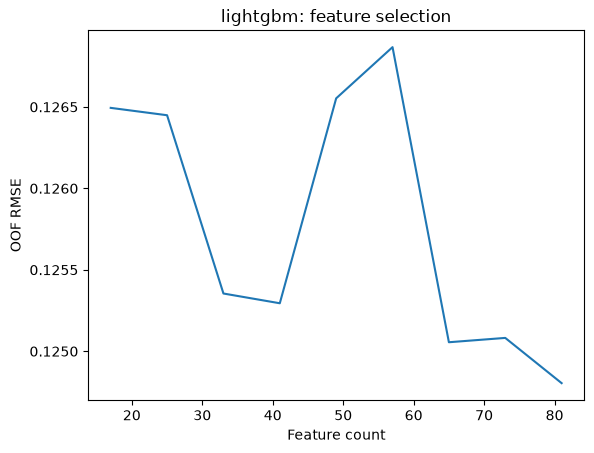

In [115]:
lightgbm_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=lightgbm_results["cv_folds"],
    importance=lightgbm_shap["importance"],
    search_results=lightgbm_results["best_results"],
    model_name="lightgbm",
    model_configs=lightgbm_pipeline,
    model_run_id=lightgbm_results["run_id"],
    logger=logger,
)

if (
    lightgbm_fs_results["best_oof_score"]
    < lightgbm_results["best_results"]["best_oof_score"]
):
    ModelSaver.save_ensemble(
        lightgbm_fs_results["best_ensemble"],
        "lightgbm",
        save_fs=lightgbm_fs_results["best_results"]["best_cols"],
    )
else:
    ModelSaver.save_ensemble(lightgbm_results["best_ensemble"], "lightgbm")

## KNN

In [163]:
knn_pipeline = {
    "knn": {
        "pipeline": Pipeline(
            [
                ("feature_transform", FeatureTransformer()),
                ("encoder", clone(encoder_transformer)),
                ("scaler", StandardScaler()),
                ("model", KNeighborsRegressor()),
            ]
        ),
        "parameters": {
            "model__n_neighbors": [8],
            "model__weights": ["distance"],
            "model__p": [1],
            "model__n_jobs": [-1],
        },
        "search_type": "grid",
        "fit_param": {},
        "n_iter": 250,
        "plot_param": "model__n_neighbors",
        "heatmap_params": ("model__n_neighbors", "model__p"),
        "shap_mode": "dnn",
        "cv": 5,
        "n_jobs": -1,
    }
}

Начинаем обучение 1 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF 0.17179213516397865, best mean val RMSE 0.17131553589880244, best_val_std 0.012514861099132867
Best searched params
model__n_jobs             -1
model__n_neighbors         8
model__p                   1
model__weights      distance


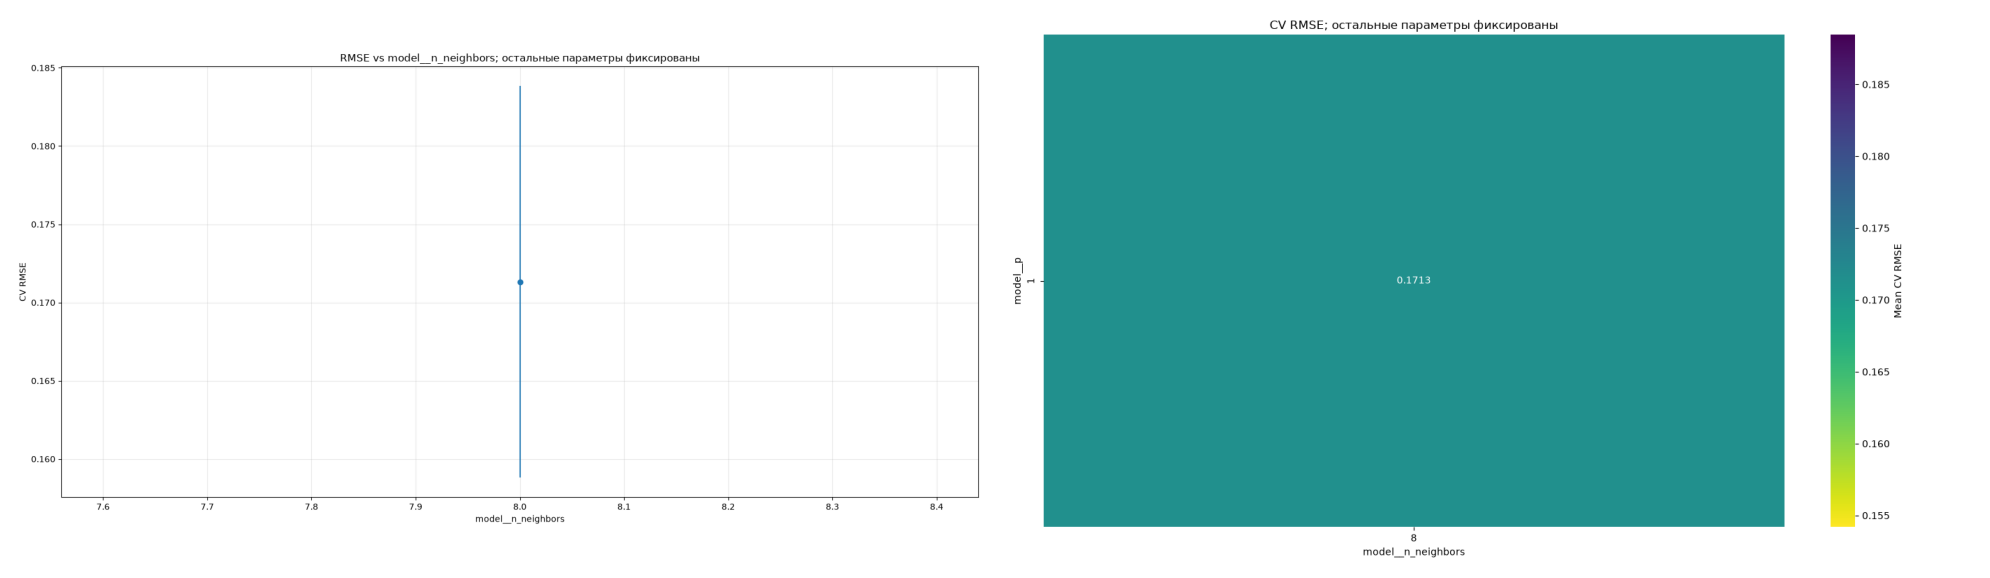

In [83]:
knn_results = run_experiment(X_train, y_train, "knn", knn_pipeline, logger)

### Optuna

In [ ]:
def suggest_knn_params(trial):
    return {
        "model__n_neighbors": trial.suggest_categorical(
            "model__n_neighbors", list(map(int, np.linspace(4, 30, 15, dtype=int)))
        ),
        "model__weights": trial.suggest_categorical(
            "model__weights", ["uniform", "distance"]
        ),
        "model__p": trial.suggest_categorical("model__p", [1, 2]),
    }


knn_optuna_pipeline = {
    "knn_optuna": {
        "pipeline": Pipeline(
            [
                ("feature_transform", FeatureTransformer()),
                ("encoder", clone(encoder_transformer)),
                ("scaler", StandardScaler()),
                ("model", KNeighborsRegressor()),
            ]
        ),
        "parameters_to_search": suggest_knn_params,
        "search_type": "grid",
        "fit_param": {"model__n_jobs": -1},
        "n_iter": 1,
        "plot_param": "model__n_neighbors",
        "heatmap_params": ("model__n_neighbors", "model__p"),
        "shap_mode": "knn",
        "cv": 5,
        "n_jobs": -1,
    }
}

In [ ]:
knn_optuna_results = run_optuna_experiment(
    X_train, y_train, "knn_optuna", knn_optuna_pipeline, logger
)

### SHAP и отбор признаков

In [ ]:
knn_optuna_shap = run_shap(X_train, knn_results, mode="dnn", logger=logger)

In [ ]:
knn_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=knn_results["cv_folds"],
    importance=knn_optuna_shap["importance"],
    search_results=knn_results["best_results"],
    model_name="knn_optuna",
    model_configs=knn_pipeline,
    model_run_id=knn_results["run_id"],
    logger=logger,
)
if knn_fs_results["best_oof_score"] < knn_results["best_results"]["best_oof_score"]:
    ModelSaver.save_ensemble(
        knn_fs_results["best_ensemble"],
        "knn",
        save_fs=knn_fs_results["best_results"]["best_cols"],
    )
else:
    ModelSaver.save_ensemble(knn_results["best_ensemble"], "knn")

## Decision Tree

In [68]:
decision_tree_pipeline = {
    "decision_tree": {
        "pipeline": Pipeline(
            [
                ("feature_transform", FeatureTransformer()),
                ("encoder", clone(encoder_transformer)),
                ("scaler", StandardScaler()),
                ("model", DecisionTreeRegressor()),
            ]
        ),
        "parameters": {
            "model__max_depth": [6, 10, 15, 20],
            "model__criterion": ["squared_error"],
            "model__splitter": ["best"],
            "model__min_samples_split": [20, 36, 50],
            "model__min_samples_leaf": [11],
            "model__max_leaf_nodes": [50],
            "model__min_impurity_decrease": [0],
            "model__random_state": [Config.seed],
        },
        "search_type": "grid",
        "fit_param": {},
        "n_iter": 250,
        "plot_param": "model__max_depth",
        "heatmap_params": ("model__max_depth", "model__min_samples_split"),
        "shap_mode": "tree",
        "cv": 5,
        "n_jobs": -1,
    }
}

Начинаем обучение 12 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

... (4 outputs left out)

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF 0.18511724237242508, best mean val RMSE 0.18463187298422806, best_val_std 0.013080136239905431
Best searched params
model__criterion              squared_error
model__max_depth                          6
model__max_leaf_nodes                    50
model__min_impurity_decrease              0
model__min_samples_leaf                  11
model__min_samples_split                 20
model__random_state                      42
model__splitter                        best


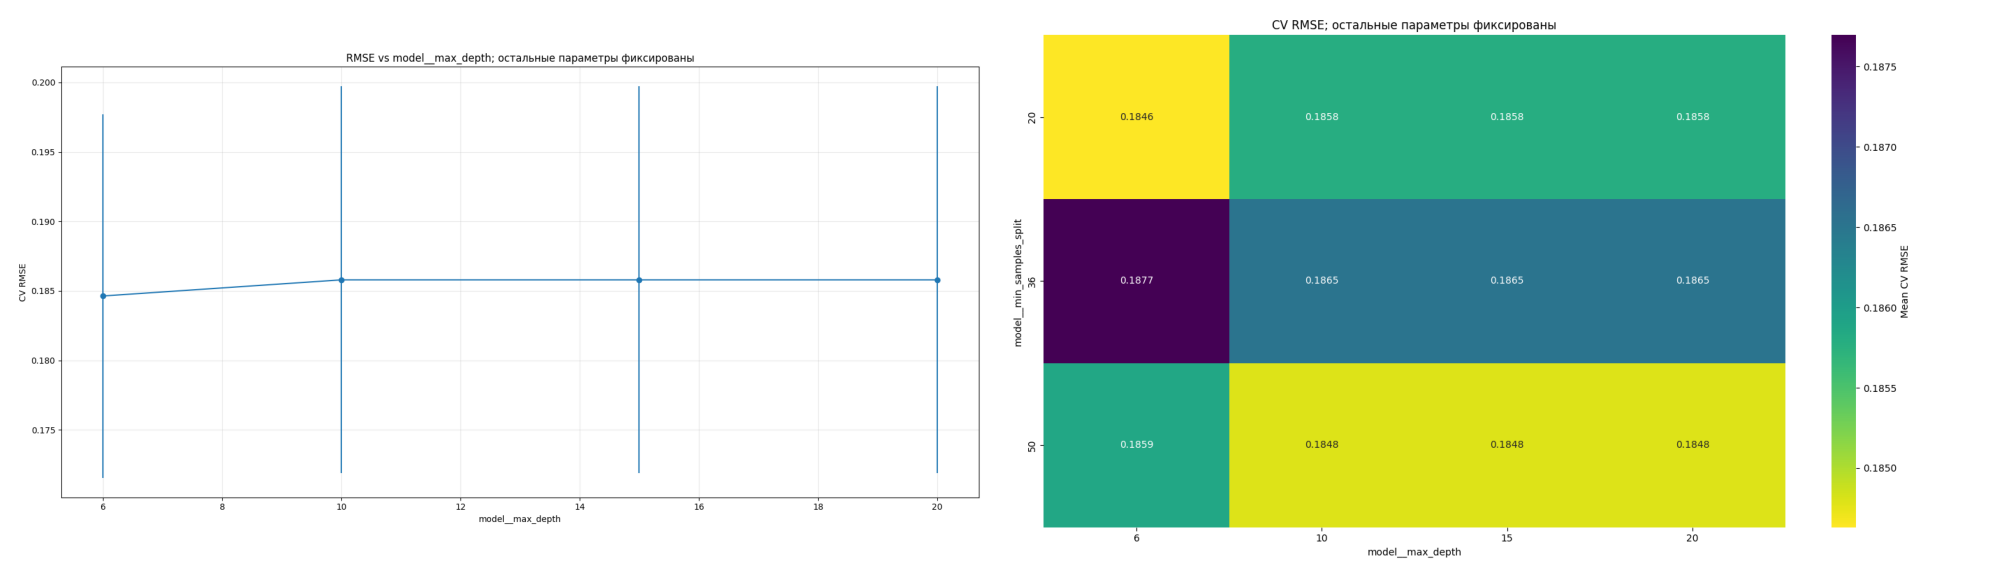

In [69]:
decision_tree_results = run_experiment(
    X_train, y_train, "decision_tree", decision_tree_pipeline, logger
)

### SHAP и отбор признаков

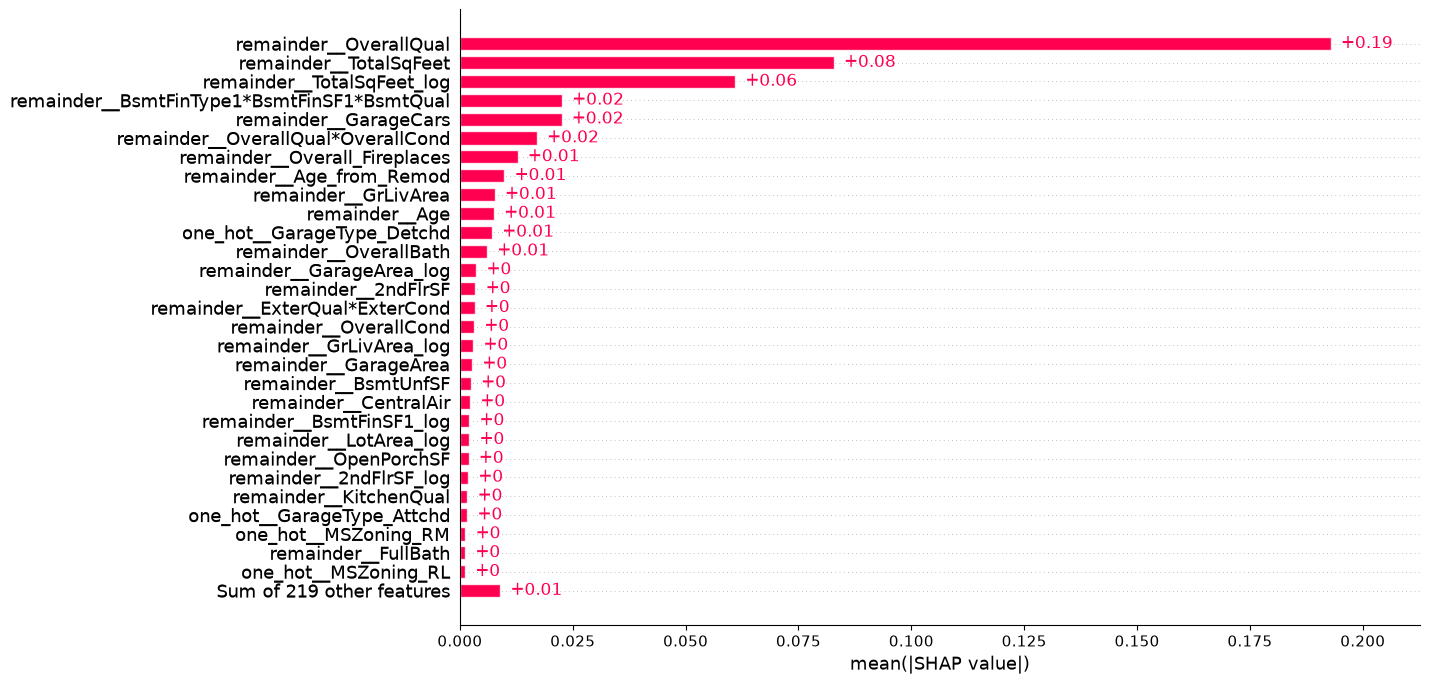

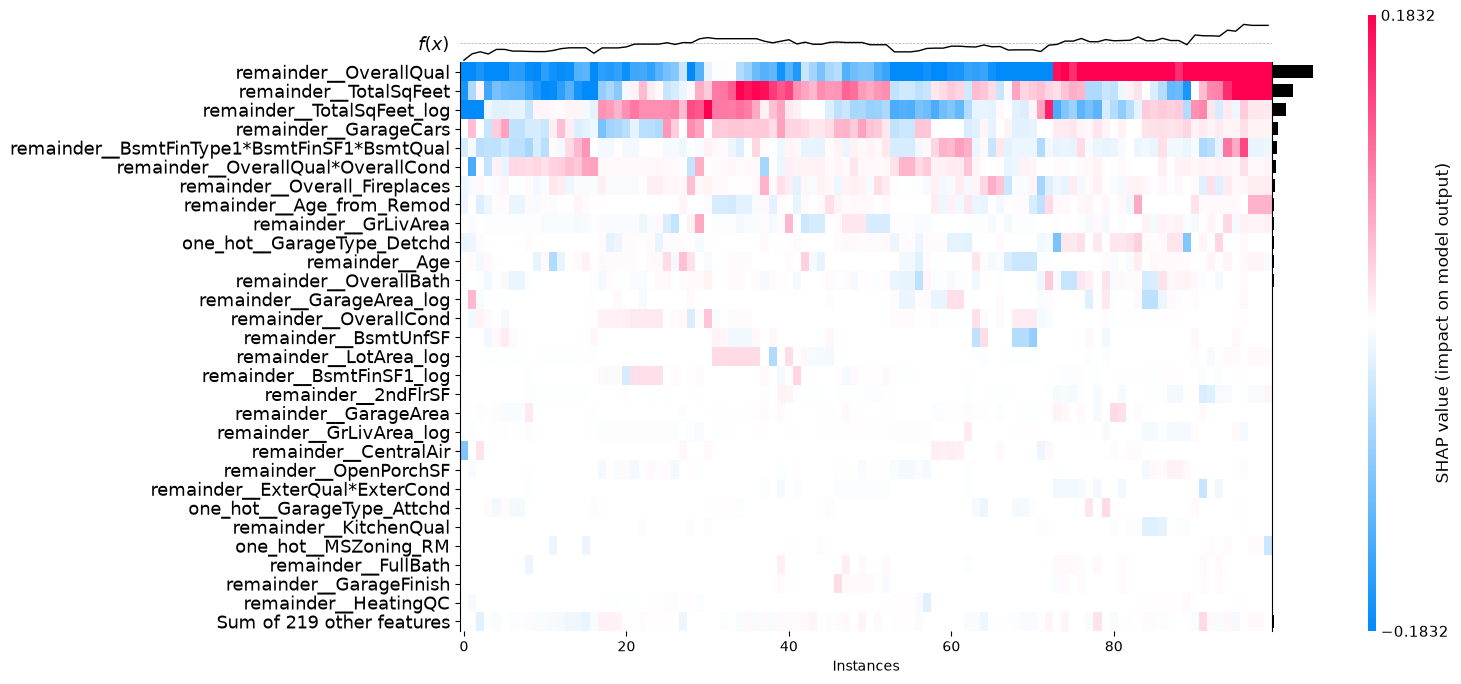

In [87]:
decision_tree_optuna_shap = run_shap(
    X_train, decision_tree_results, mode="tree", logger=logger
)

Мне кажется для дерева тут слишком много параметров для дерева

## Random Forest

In [87]:
random_forest_pipeline = {
    "random_forest": {
        "pipeline": Pipeline(
            [
                ("feature_transform", FeatureTransformer()),
                ("encoder", clone(encoder_transformer)),
                ("scaler", StandardScaler()),
                ("model", RandomForestRegressor()),
            ]
        ),
        "parameters": {
            # bootstrap=True
            "model__n_estimators": [1000],  # np.linspace(1, 100, 5, dtype=int)
            "model__max_depth": [14],  # 13
            "model__criterion": ["squared_error"],
            "model__n_jobs": [-1],
            "model__min_samples_split": [10],  # np.linspace(10, 100, 5, dtype=int)
            "model__min_samples_leaf": [
                5
            ],  # np.linspace(5, 15, 5, dtype=int); min_samples_leaf: np.int64(6)
            "model__max_leaf_nodes": [100],  # 75
            "model__min_impurity_decrease": [0],
            "model__max_features": np.linspace(0.1, 1, 10),  # "sqrt", "log2"
            "model__bootstrap": [True],
            "model__max_samples": [0.8],
            "model__oob_score": [True],
            "model__random_state": [Config.seed],
        },
        "search_type": "grid",
        "fit_param": {},
        "n_iter": 250,
        "plot_param": "model__max_features",
        "heatmap_params": ("model__max_leaf_nodes", "model__max_depth"),
        "shap_mode": "tree",
        "cv": 5,
        "n_jobs": -1,
    }
}

Начинаем обучение 10 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

... (2 outputs left out)

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF 0.1390763013447038, best mean val RMSE 0.13785143576540382, best_val_std 0.018164137023746658
Best searched params
model__bootstrap                       True
model__criterion              squared_error
model__max_depth                         14
model__max_features                     0.3
model__max_leaf_nodes                   100
model__max_samples                      0.8
model__min_impurity_decrease              0
model__min_samples_leaf                   5
model__min_samples_split                 10
model__n_estimators                    1000
model__n_jobs                            -1
model__oob_score                       True
model__random_state                      42


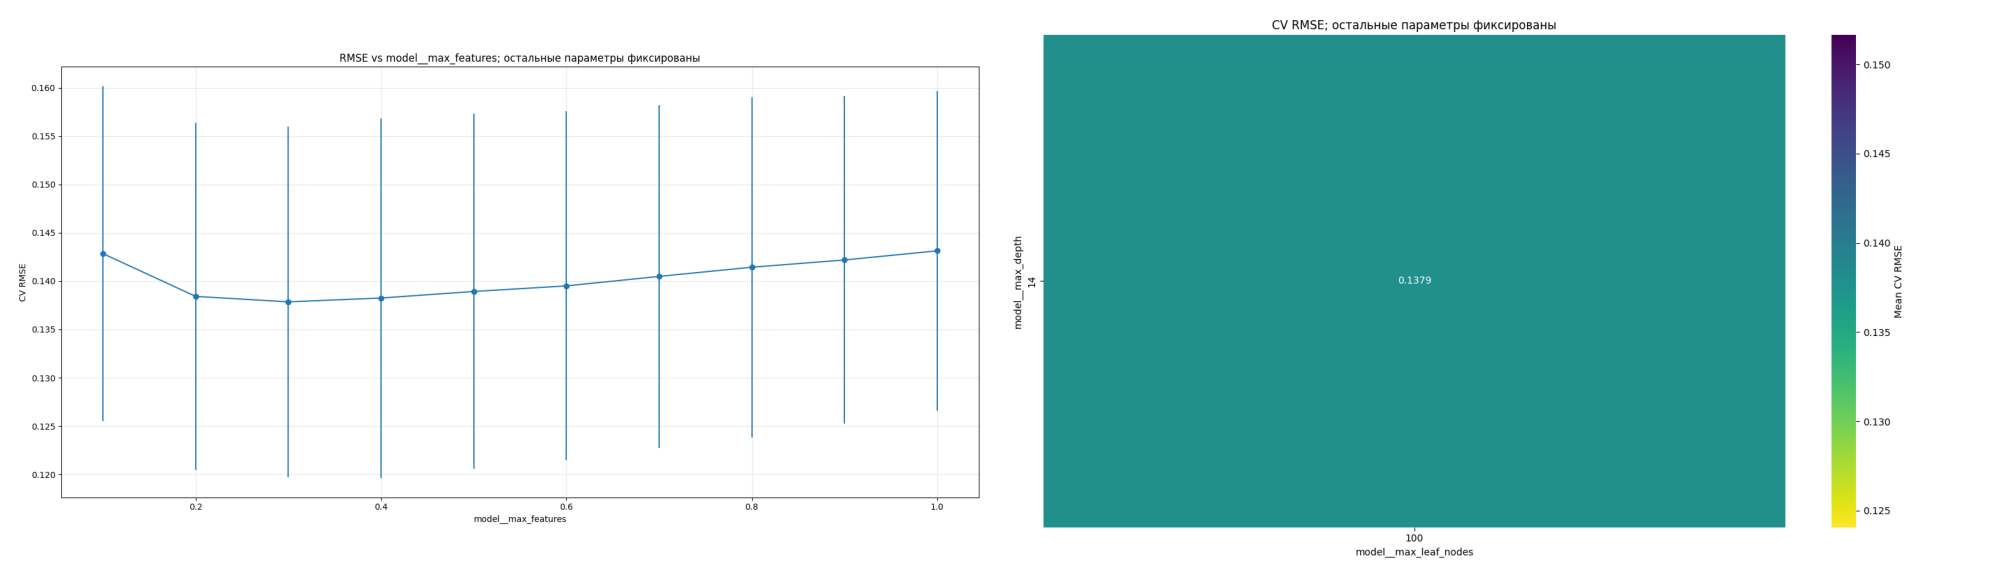

In [88]:
random_forest_results = run_experiment(
    X_train, y_train, "random_forest", random_forest_pipeline, logger
)
ModelSaver.save_ensemble(random_forest_results["best_ensemble"], "random_forest")

### Optuna

In [ ]:
def suggest_random_forest_params(trial):
    return {
        "model__n_estimators": trial.suggest_int(
            "model__n_estimators", 100, 2000, step=100
        ),
        "model__max_depth": trial.suggest_int("model__max_depth", 10, 20, step=1),
        "model__min_samples_split": trial.suggest_int(
            "model__min_samples_split", 5, 50, step=5
        ),
        "model__min_samples_leaf": trial.suggest_int(
            "model__min_samples_leaf", 5, 50, step=5
        ),
        "model__max_leaf_nodes": trial.suggest_int(
            "model__max_leaf_nodes", 50, 100, step=5
        ),
        "model__min_impurity_decrease": trial.suggest_float(
            "model__min_impurity_decrease",
            0.01,
            20,
            log=True,
        ),
        "model__max_features": trial.suggest_categorical(
            "model__max_features", [0.4, 0.6, 0.8, 1.0]
        ),
        "model__max_samples": trial.suggest_categorical(
            "model__max_samples", [0.4, 0.6, 0.8, 1.0]
        ),
        "model__oob_score": trial.suggest_categorical(
            "model__oob_score", [True, False]
        ),
    }


random_forest_optuna_pipeline = {
    "random_forest_optuna": {
        "pipeline": Pipeline(
            [
                ("feature_transform", FeatureTransformer()),
                ("encoder", clone(encoder_transformer)),
                ("scaler", StandardScaler()),
                ("model", RandomForestRegressor()),
            ]
        ),
        "parameters_to_search": suggest_random_forest_params,
        "search_type": "grid",
        "fit_param": {
            "model__n_jobs": -1,
            "model__random_state": Config.seed,
            "model__bootstrap": True,
            "model__criterion": "squared_error",
        },
        "n_iter": 300,
        "plot_param": "model__n_estimators",
        "heatmap_params": ("model__n_estimators", "model__max_depth"),
        "shap_mode": "tree",
        "cv": 5,
        "n_jobs": -1,
    }
}

In [ ]:
random_forest_optuna_results = run_optuna_experiment(
    X_train, y_train, "random_forest_optuna", random_forest_optuna_pipeline, logger
)

### SHAP и отбор признаков

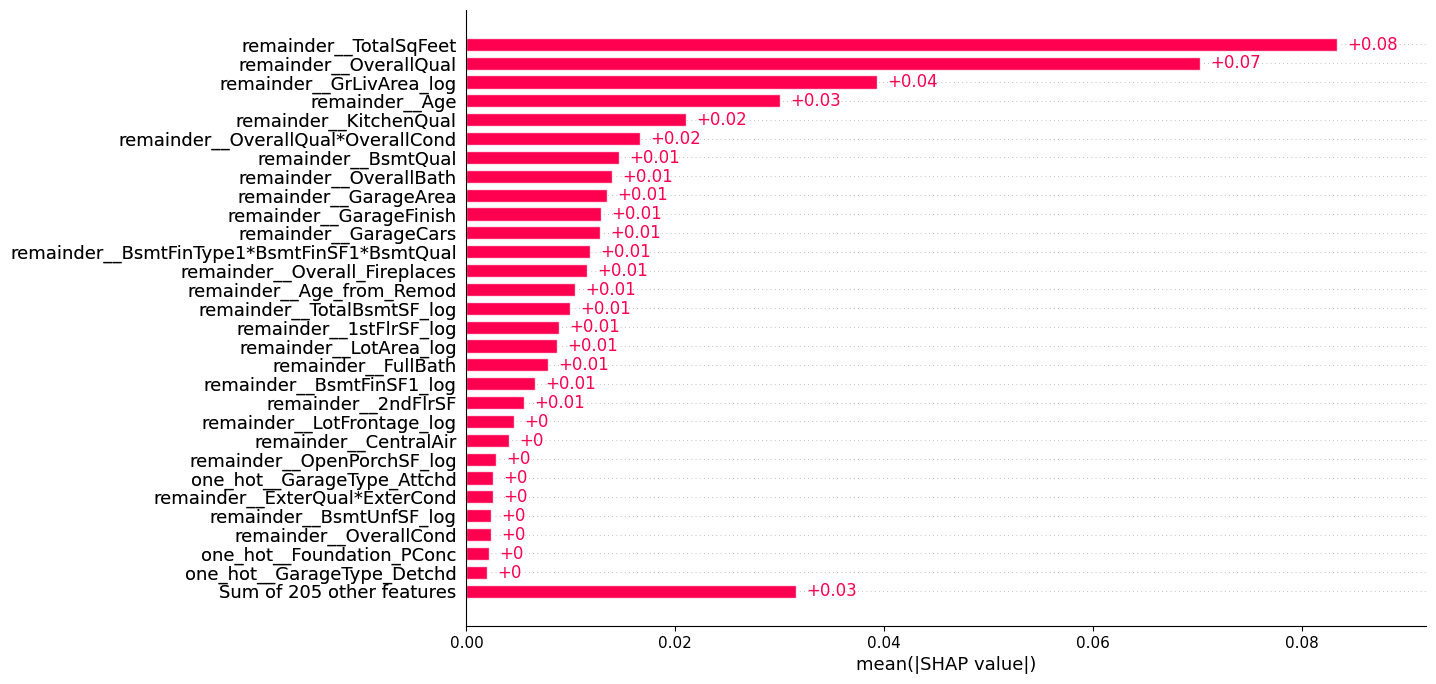

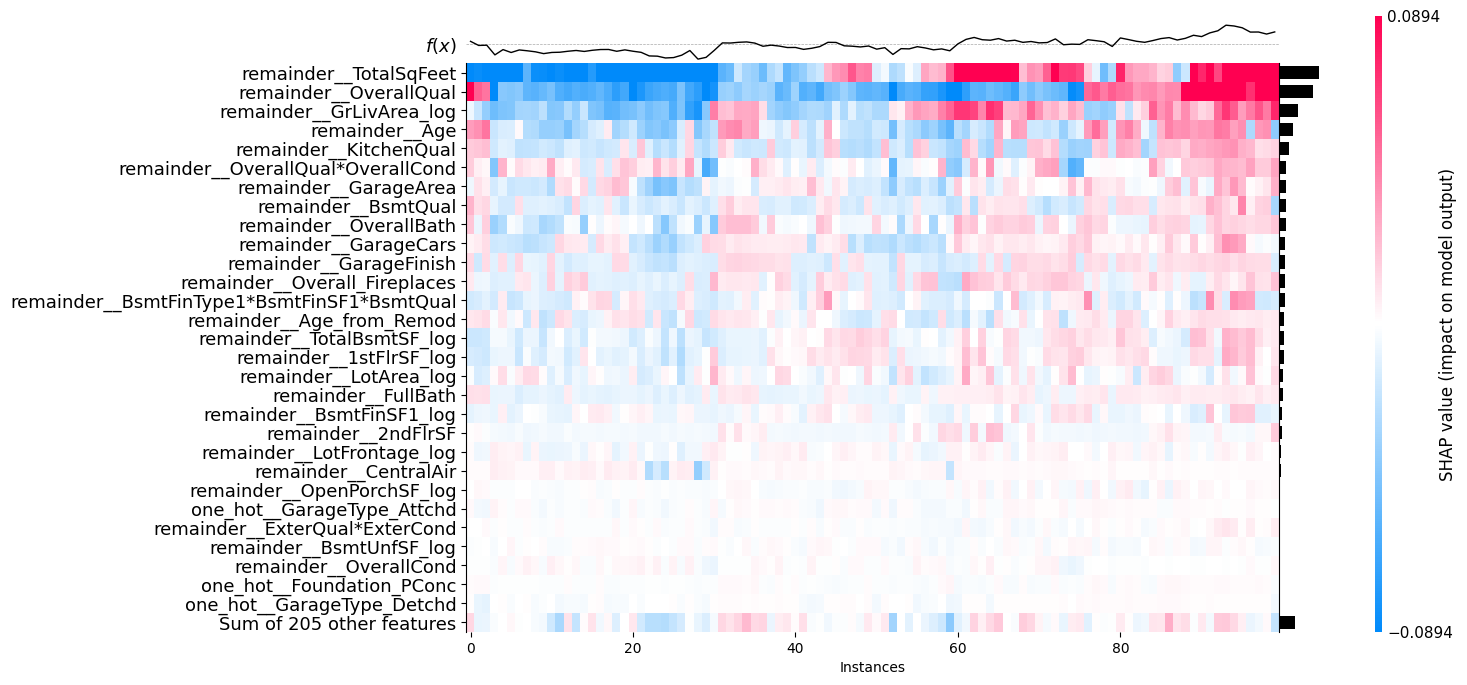

In [89]:
random_forest_shap = run_shap(
    X_train, random_forest_results, mode="tree", logger=logger
)

Отбор кол-ва фичей для одного дерева устанавливается в случайном лесе как параметр обучения, поэтому проводить его еще раз отдельно я считаю бесполезно

## XGBoost

In [172]:
xgboost_pipeline = {
    "xgboost": {
        "pipeline": Pipeline(
            [
                ("feature_transform", FeatureTransformer()),
                ("encoder", clone(encoder_transformer)),
                ("scaler", StandardScaler()),
                ("model", XGBRegressor()),
            ]
        ),
        "parameters": {
            "model__device": ["cuda"],
            "model__booster": ["gbtree"],
            "model__tree_method": ["hist"],
            "model__n_estimators": [
                1000
            ],  # np.linspace(1, 100, 5, dtype=int); лучшее 12
            "model__learning_rate": [
                np.float64(0.013190161120540767)
            ],  # [np.float64(0.0775)]
            "model__max_depth": [
                6
            ],  # [6, 8, 10, 12, 14]; лучшее 10 для случайного леса
            "model__min_child_weight": [
                0.03794613934217169
            ],  # np.linspace(1, 10, 5, dtype=int)
            "model__n_jobs": [1],
            "model__subsample": [0.4],  # [0.6, 0.8, 1.0]
            "model__colsample_bytree": [0.75],  # [0.65, 0.7, 0.75]
            "model__reg_alpha": [0.0193336968922133],  # [0, 0.01, 0.1, 1]
            "model__reg_lambda": [0.032333649917330995],  # [0.01, 0.1, 0.5, 5, 10]
            "model__gamma": [0.017362357647552687],  # np.linspace(0.01, 0.1, 10)
            "model__objective": ["reg:squarederror"],
            "model__eval_metric": ["rmse"],  # RMSE для регрессии
            "model__random_state": [Config.seed],
        },
        "search_type": "grid",
        "fit_param": {},
        "n_iter": 1,
        "plot_param": "model__learning_rate",
        "heatmap_params": ("model__learning_rate", "model__n_estimators"),
        "shap_mode": "tree",
        "cv": 5,
        "n_jobs": 1,
    }
}

Начинаем обучение 1 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\xgboost\core.py:751: UserWarning: [02:24:32] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Best OOF 0.12604402540338036, best mean val RMSE 0.1241406061826846, best_val_std 0.021596274925949652
Best searched params
model__booster                     gbtree
model__colsample_bytree              0.75
model__device                        cuda
model__eval_metric                   rmse
model__gamma                     0.017362
model__learning_rate              0.01319
model__max_depth                        6
model__min_child_weight          0.037946
model__n_estimators                  1000
model__n_jobs                           1
model__objective         reg:squarederror
model__random_state                    42
model__reg_alpha                 0.019334
model__reg_lambda                0.032334
model__subsample                      0.4
model__tree_method                   hist


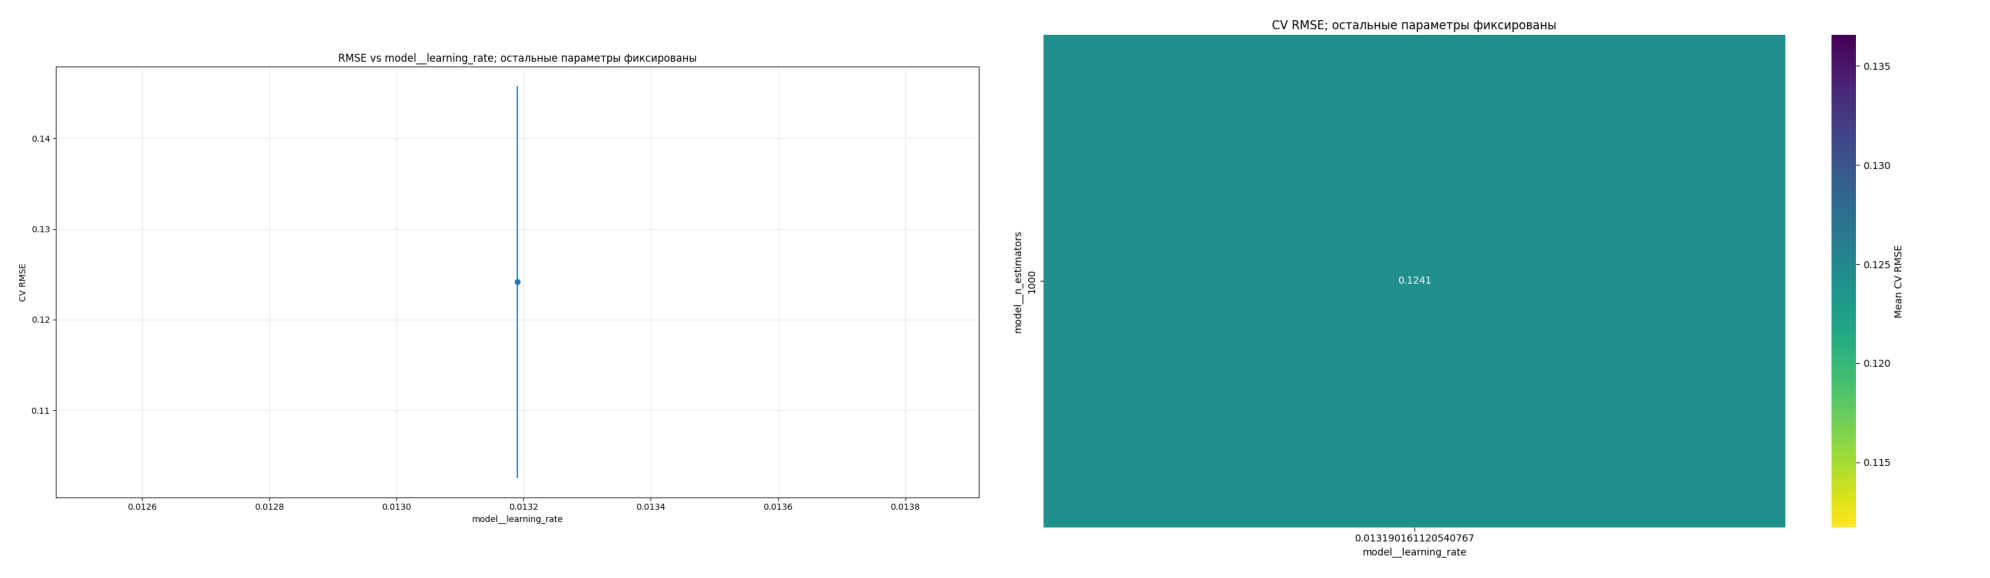

In [173]:
xgboost_results = run_experiment(X_train, y_train, "xgboost", xgboost_pipeline, logger)
ModelSaver.save_ensemble(xgboost_results["best_ensemble"], "xgboost")

### Optuna

In [ ]:
def suggest_xgboost_params(trial):
    return {
        "model__booster": trial.suggest_categorical("model__booster", ["gbtree"]),
        "model__tree_method": trial.suggest_categorical("model__tree_method", ["hist"]),
        "model__n_estimators": trial.suggest_categorical("model__n_estimators", [1000]),
        "model__learning_rate": trial.suggest_float(
            "model__learning_rate",
            0.001,
            0.10,
            log=True,
        ),
        "model__max_depth": trial.suggest_categorical(
            "model__max_depth", [4, 5, 6, 7, 8]
        ),
        "model__min_child_weight": trial.suggest_float(
            "model__min_child_weight",
            0.01,
            20,
            log=True,
        ),
        "model__subsample": trial.suggest_categorical(
            "model__subsample", [0.4, 0.5, 0.6, 0.8, 1]
        ),
        "model__reg_alpha": trial.suggest_float(
            "model__reg_alpha",
            0.001,
            0.10,
            log=True,
        ),
        "model__reg_lambda": trial.suggest_float(
            "model__reg_lambda",
            0.001,
            0.10,
            log=True,
        ),
        "model__gamma": trial.suggest_float(
            "model__gamma",
            0.01,
            0.1,
            log=True,
        ),
        "model__colsample_bytree": trial.suggest_categorical(
            "model__colsample_bytree", [0.5, 0.65, 0.7, 0.75, 0.8, 1]
        ),
    }


xgboost_optuna_pipeline = {
    "xgboost_optuna": {
        "pipeline": Pipeline(
            [
                ("feature_transform", FeatureTransformer()),
                ("encoder", clone(encoder_transformer)),
                ("scaler", StandardScaler()),
                ("model", XGBRegressor()),
            ]
        ),
        "parameters_to_search": suggest_xgboost_params,
        "search_type": "grid",
        "fit_param": {
            "model__device": "cuda",
            "model__n_jobs": -1,
            "model__random_state": Config.seed,
            "model__objective": "reg:squarederror",
            "model__eval_metric": "rmse",
        },
        "n_iter": 500,
        "plot_param": "model__learning_rate",
        "heatmap_params": ("model__learning_rate", "model__n_estimators"),
        "shap_mode": "tree",
        "cv": 5,
        "n_jobs": -1,
    }
}

In [ ]:
xgboost_optuna_results = run_optuna_experiment(
    X_train, y_train, "xgboost_optuna", xgboost_optuna_pipeline, logger
)

### SHAP и отбор признаков

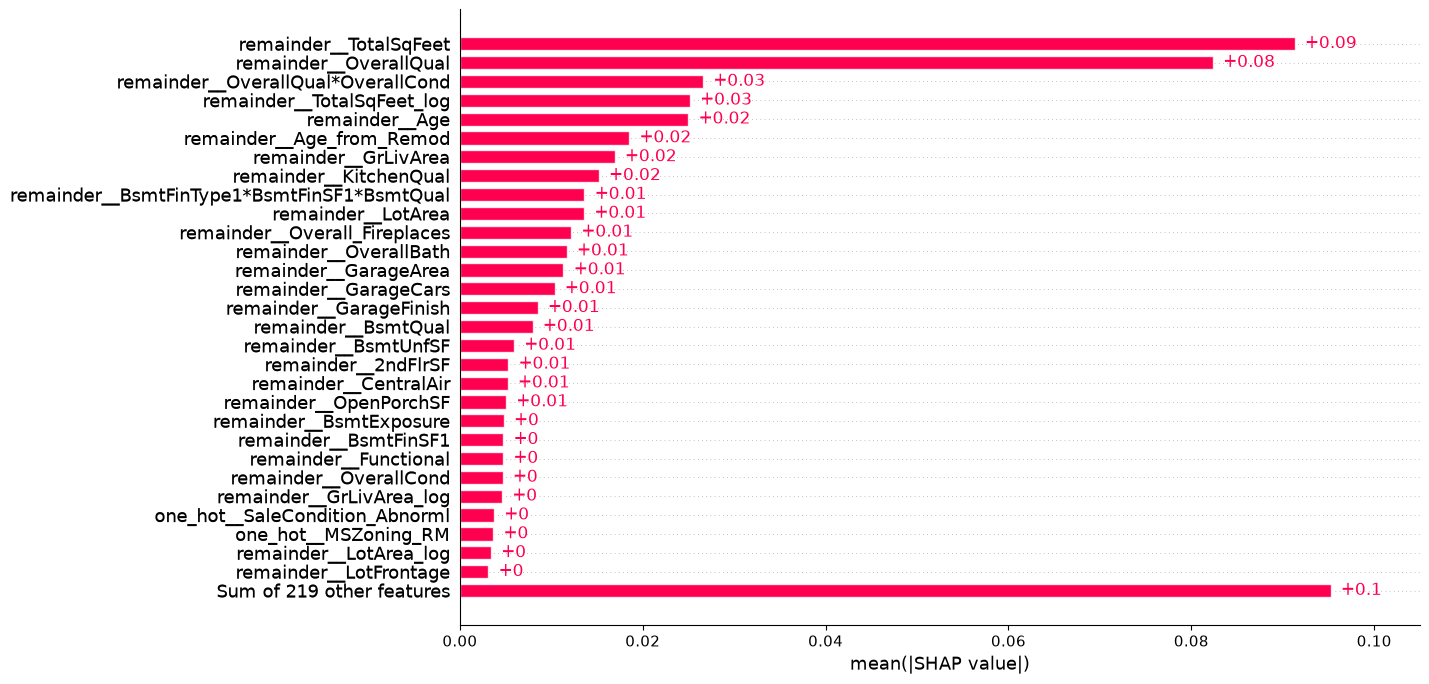

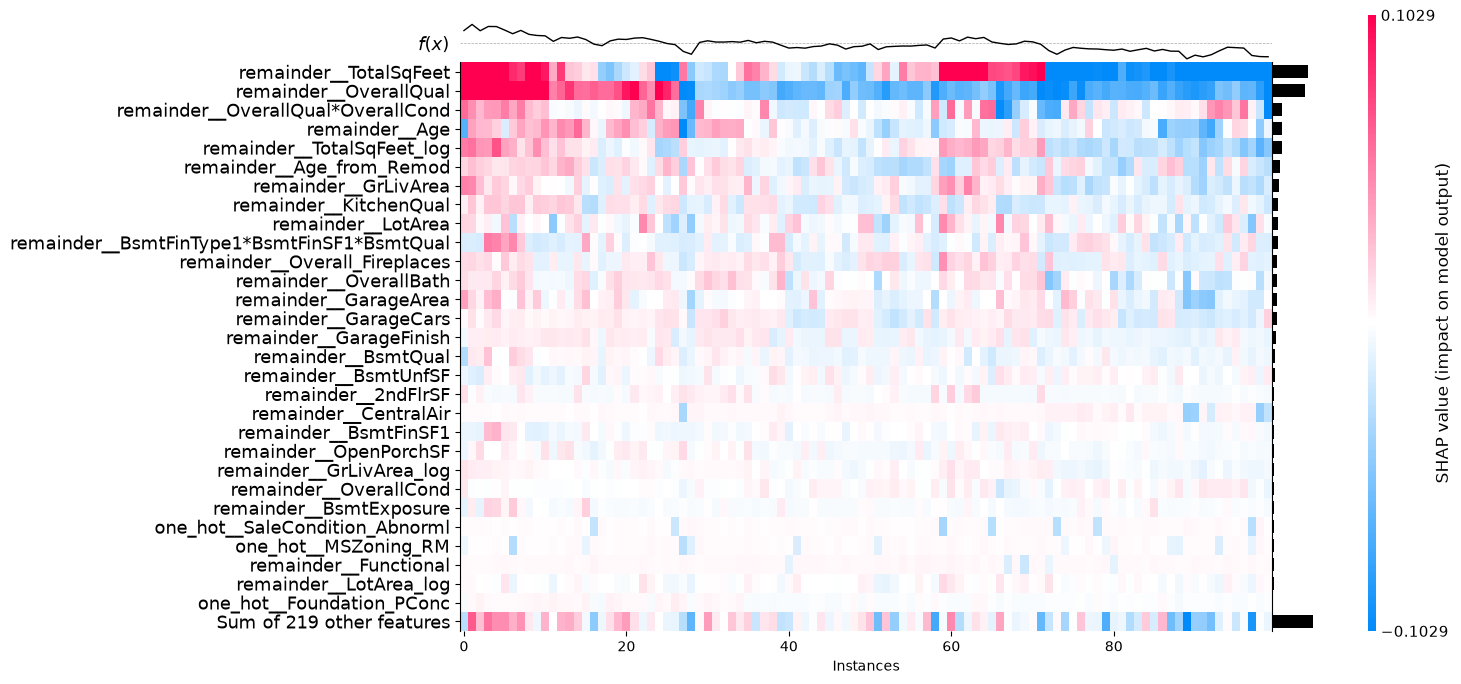

In [123]:
xgboost_shap = run_shap(X_train, xgboost_results, mode="tree", logger=logger)

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF: 0.1254597551093981, best mean val RMSE: 0.1233197247292304, best val std: 0.0228473012320703, best feature amount: 33
-----Best searched params-----
model__booster                     gbtree
model__colsample_bytree              0.75
model__device                        cuda
model__eval_metric                   rmse
model__gamma                     0.017362
model__learning_rate              0.01319
model__max_depth                        6
model__min_child_weight          0.037946
model__n_estimators                  1000
model__n_jobs                           1
model__objective         reg:squarederror
model__random_state                    42
model__reg_alpha                 0.019334
model__reg_lambda                0.032334
model__subsample                      0.4
model__tree_method                   hist


,params,off_score,mean_val_score,std_val_score,feature_count,split0_val_score,split1_val_score,split2_val_score,split3_val_score,split4_val_score,...,param_model__min_child_weight,param_model__n_estimators,param_model__n_jobs,param_model__objective,param_model__random_state,param_model__reg_alpha,param_model__reg_lambda,param_model__subsample,param_model__tree_method,candidate_id
6,"{'model__booster': 'gbtree', 'model__colsample...",0.125460,0.123320,0.022847,113,0.125060,0.139149,0.155981,0.101956,0.094454,...,0.037946,1000,1,reg:squarederror,42,0.019334,0.032334,0.4,hist,6
0,"{'model__booster': 'gbtree', 'model__colsample...",0.125903,0.124175,0.020568,224,0.124434,0.136715,0.155308,0.105639,0.098778,...,0.037946,1000,1,reg:squarederror,42,0.019334,0.032334,0.4,hist,0
3,"{'model__booster': 'gbtree', 'model__colsample...",0.126196,0.124299,0.021569,180,0.126663,0.137569,0.155971,0.103989,0.097303,...,0.037946,1000,1,reg:squarederror,42,0.019334,0.032334,0.4,hist,3
2,"{'model__booster': 'gbtree', 'model__colsample...",0.126289,0.124468,0.021139,200,0.125574,0.138974,0.155154,0.103482,0.099158,...,0.037946,1000,1,reg:squarederror,42,0.019334,0.032334,0.4,hist,2
5,"{'model__booster': 'gbtree', 'model__colsample...",0.126699,0.124764,0.021835,129,0.124899,0.139732,0.156808,0.104478,0.097903,...,0.037946,1000,1,reg:squarederror,42,0.019334,0.032334,0.4,hist,5
1,"{'model__booster': 'gbtree', 'model__colsample...",0.126910,0.125118,0.021025,215,0.126342,0.137245,0.157110,0.104701,0.100193,...,0.037946,1000,1,reg:squarederror,42,0.019334,0.032334,0.4,hist,1
4,"{'model__booster': 'gbtree', 'model__colsample...",0.127185,0.125290,0.021642,166,0.128162,0.138931,0.156615,0.104687,0.098054,...,0.037946,1000,1,reg:squarederror,42,0.019334,0.032334,0.4,hist,4
7,"{'model__booster': 'gbtree', 'model__colsample...",0.127958,0.126026,0.021920,86,0.127029,0.142028,0.157189,0.104603,0.099282,...,0.037946,1000,1,reg:squarederror,42,0.019334,0.032334,0.4,hist,7
8,"{'model__booster': 'gbtree', 'model__colsample...",0.128733,0.126768,0.022173,41,0.128235,0.146528,0.155398,0.103020,0.100657,...,0.037946,1000,1,reg:squarederror,42,0.019334,0.032334,0.4,hist,8


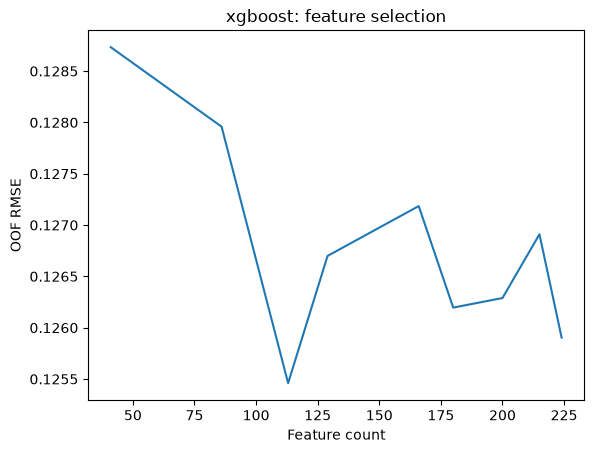

In [124]:
xgboost_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=xgboost_results["cv_folds"],
    importance=xgboost_shap["importance"],
    search_results=xgboost_results["best_results"],
    model_name="xgboost",
    model_configs=xgboost_pipeline,
    model_run_id=xgboost_results["run_id"],
    logger=logger,
)

if (
    xgboost_fs_results["best_oof_score"]
    < xgboost_results["best_results"]["best_oof_score"]
):
    ModelSaver.save_ensemble(
        xgboost_fs_results["best_ensemble"],
        "xgboost",
        save_fs=xgboost_fs_results["best_results"]["best_cols"],
    )
else:
    ModelSaver.save_ensemble(xgboost_results["best_ensemble"], "xgboost")

## Stacking Ridge

In [94]:
ridge_params = {
    "parameters": {
        "model__alpha": np.float64(0.11144234247204798),
        "model__solver": "saga",
        "model__max_iter": 1000,
        "model__random_state": Config.seed,
    },
    "fit_param": {},
}

xgb_params = {
    "parameters": {
        "model__device": "cuda",
        "model__booster": "gbtree",
        "model__tree_method": "hist",
        "model__n_estimators": 1000,
        "model__learning_rate": np.float64(0.013190161120540767),
        "model__max_depth": 6,
        "model__min_child_weight": 0.03794613934217169,
        "model__n_jobs": 1,
        "model__subsample": 0.4,
        "model__colsample_bytree": 0.75,
        "model__reg_alpha": 0.0193336968922133,
        "model__reg_lambda": 0.032333649917330995,
        "model__gamma": 0.017362357647552687,
        "model__objective": "reg:squarederror",
        "model__eval_metric": "rmse",
        "model__random_state": Config.seed,
    },
    "fit_param": {},
}

rf_params = {
    "parameters": {
        "model__n_estimators": 1000,
        "model__max_depth": 14,
        "model__criterion": "squared_error",
        "model__n_jobs": -1,
        "model__min_samples_split": 10,
        "model__min_samples_leaf": 5,
        "model__max_leaf_nodes": 100,
        "model__min_impurity_decrease": 0,
        "model__max_features": 0.3,
        "model__bootstrap": True,
        "model__max_samples": 0.8,
        "model__oob_score": True,
        "model__random_state": Config.seed,
    },
    "fit_param": {},
}

lgbm_params = {
    "parameters": {
        "model__device": "cpu",
        "model__boosting_type": "gbdt",
        "model__n_estimators": 2000,
        "model__learning_rate": 0.098,
        "model__max_depth": 4,
        "model__subsample": 0.4,
        "model__colsample_bytree": 0.8,
        "model__reg_alpha": 0.008,
        "model__reg_lambda": 0.04000000000000001,
        "model__objective": "regression",
        "model__metric": "rmse",
        "model__min_child_samples": 40,
        "model__min_child_weight": 1,
        "model__min_split_gain": 0.0005,
        "model__n_jobs": -1,
        "model__random_state": Config.seed,
        "model__verbosity": -1,
        "model__early_stopping_round": 30,
    },
    "fit_param": {},
}

cat_params = {
    "parameters": {
        "model__boosting_type": "Plain",
        "model__iterations": 1000,
        "model__learning_rate": 0.05211448378065621,
        "model__depth": 4,
        "model__bootstrap_type": "Bernoulli",
        "model__thread_count": -1,
        "model__l2_leaf_reg": 0.01727277227745447,
        "model__rsm": 1.0,
        "model__subsample": 0.8,
        "model__border_count": 256,
        "model__min_data_in_leaf": 50,
        "model__max_ctr_complexity": 2,
        "model__one_hot_max_size": 6,
        "model__eval_metric": "RMSE",
        "model__loss_function": "RMSE",
        "model__random_strength": 1.7444045228543141,
        "model__verbose": False,
        "model__random_seed": Config.seed,
        "model__early_stopping_rounds": 50,
    },
    "fit_param": {"model__cat_features": FeatureTransformer.cat_cols},
}

dnn_params = {
    "parameters": {
        "model__cat_cols": FeatureTransformer.cat_cols,
        "model__num_cols": FeatureTransformer.num_cols,
        "model__epochs": 1000,
        "model__device": Config.device,
        "model__emb_dim": 24,
        "model__inner_n": 256,
        "model__drop_n": 0.2,
        "model__n_layers": 1,
        "model__use_batchnorm": True,
        "model__loss_reg": RMSELoss,
        "model__l1_lambda": 0.023081011668103977,
        "model__optim": torch.optim.Adam,
        "model__optim_lr": 0.06343656703028737,
        "model__scheduler": torch.optim.lr_scheduler.ReduceLROnPlateau,
        "model__lr_scheduler": True,
        "model__factor": 0.09023739101987314,
        "model__patience": 20,
        "model__threshold": 0.01,
        "model__min_lr": 1e-10,
        "model__early_stopping_patience": 45,
        "model__early_stopping_threshold": 0.001,
        "model__batch_size": 32,
        "model__saving_threshold": 0.001,
        "model__save_path": "checkpoints",
    },
    "fit_param": {
        "model__callbacks": [CheckpointManager(), EarlyStopping()],
    },
}

# ridge_meta_params = {
#         "parameters": {
#             "model__alpha": np.float64(0.11144234247204798),
#             "model__solver": "saga",
#             "model__max_iter": 1000,
#             "model__random_state": Config.seed,
#         },
#         "fit_param": {}
#     }
# ------------------------------------------------------------------------------------------------------------------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=Config.seed)
cv_folds = list(kf.split(X_train, y_train))


start_val = 0.001
stop_val = 100

meta_params = np.logspace(
    np.log10(start_val), np.log10(stop_val), num=1
)  # np.linspace(0.001,10,100)
best_oof = +float("inf")
best_alpha = 0
best_meta = None

for a in meta_params:
    ridge_meta_params = {
        "parameters": {
            "model__alpha": 0.001,
            "model__solver": "saga",
            "model__max_iter": 1000,
            "model__random_state": Config.seed,
        },
        "fit_param": {},
    }

    meta_ridge = MyStackingRidge(
        groups={"avg_boost": ["xgb", "catboost", "lightgbm"]},
        meta_cols=["avg_boost", "rf", "dnn", "ridgebase"],
        return_mean=False,
    )  # ,'{"avg_boost": ["xgb", "catboost", "lightgbm"]} , ["xgb", "catboost", "lightgbm", "rf", "dnn", "ridgebase"]
    meta_ridge.fit_sub_models(
        X_train,
        y_train,
        rf_params,
        dnn_params,
        cat_params,
        lgbm_params,
        xgb_params,
        ridge_params,
        cv_folds,
        Config.seed,
    )

    meta_res = meta_ridge.fit(
        X_train, y_train, ridge_meta_params, cv_folds, Config.seed
    )

    if meta_res["oof_rmse"] < best_oof:
        best_oof = meta_res["oof_rmse"]
        best_alpha = a
        best_meta = meta_ridge

    print(f"Скор текущей итерации {meta_res['oof_rmse']}\n")

print(f"Лучший OFF {best_oof}, лучший альфа {best_alpha}")
ModelSaver.save_ensemble([best_meta], "meta_ridge")

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Обучился xgb


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Обучился catboost


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Обучился lightgbm


... (13 outputs left out)

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Обучился ridgebase


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Скор текущей итерации 0.1218134316180402

Лучший OFF 0.1218134316180402, лучший альфа 0.001


Самым сильным по скору решением стал беггинг бустингов и обучение на нем (с добавлением случайного леса и нейросети) мне кажется это неплохой баланс и он дал хорошие результаты на LB. Можно было бы сделать результаты лучше если попробовтаь обучить не просто линейную модель, а какой нибудь бустинг, но это все очень долго учиться, в следствии очень долго подбирать гиперпараметры

In [91]:
print(f"Лучший OFF {best_oof}, лучший альфа {best_alpha}")

Лучший OFF 0.121156183892136, лучший альфа 0.001


## Hold-out results

In [92]:
saved_models = ModelSaver.upload_saved_models(Config.path_to_save_models)


Model: catboost
РќР°Р№РґРµРЅС‹ РјРѕРґРµР»Рё
Selected features: all

Model: DNN
РќР°Р№РґРµРЅС‹ РјРѕРґРµР»Рё
Selected features: 68

Model: lasso
РќР°Р№РґРµРЅС‹ РјРѕРґРµР»Рё
Selected features: all

Model: lightgbm
РќР°Р№РґРµРЅС‹ РјРѕРґРµР»Рё
Selected features: all

Model: meta_ridge
РќР°Р№РґРµРЅС‹ РјРѕРґРµР»Рё
Selected features: all

Model: random_forest
РќР°Р№РґРµРЅС‹ РјРѕРґРµР»Рё
Selected features: all

Model: ridge
РќР°Р№РґРµРЅС‹ РјРѕРґРµР»Рё
Selected features: all

Model: xgboost
РќР°Р№РґРµРЅС‹ РјРѕРґРµР»Рё
Selected features: all


In [93]:
Predictor.run_test(saved_models, X_holdout, y_holdout)
print()

        model  holdout_log_rmse
        lasso           0.11975
      xgboost           0.12361
        ridge           0.12528
   meta_ridge           0.12652
     catboost           0.12675
     lightgbm           0.13408
          DNN           0.13617
random_forest           0.14793

